<div align="center">

# 🏥 ReadmitRadar
### Predicting 30-Day Hospital Readmission with a Neural Network — Built from First Principles

![Python](https://img.shields.io/badge/Python-3.10%2B-3776AB?logo=python&logoColor=white)
![TensorFlow](https://img.shields.io/badge/TensorFlow-2.x-FF6F00?logo=tensorflow&logoColor=white)
![Keras](https://img.shields.io/badge/Keras-Sequential%20API-D00000?logo=keras&logoColor=white)
![scikit--learn](https://img.shields.io/badge/scikit--learn-Preprocessing-F7931E?logo=scikit-learn&logoColor=white)
![Status](https://img.shields.io/badge/Status-Complete-success)
![License](https://img.shields.io/badge/License-MIT-blue.svg)

*An end-to-end binary classification project that goes beyond `model.fit()` — manually deriving forward propagation, comparing loss functions from first principles, and running five documented regularization trials to fight overfitting on real-shaped clinical data.*

**[Notebook](#)** &nbsp;·&nbsp; **[Dataset](#data-dictionary)** &nbsp;·&nbsp; **[Architecture](#5-advanced-training-strategies--final-model)** &nbsp;·&nbsp; **[Results](#final-report-summary-of-findings-and-recommendations)** &nbsp;·&nbsp; **[Author](#author)**

</div>

---


# Neural Network Project: Predicting 30-Day Hospital Readmission

### Binary Classification: Readmitted within 30 days (1) vs Not Readmitted (0)


## Table of Contents

1. [Project Description](#project-description)
2. [Data Dictionary](#data-dictionary)
3. [Environment & Setup](#environment--setup)
4. [Data Understanding & Preprocessing](#1-data-understanding--preprocessing)
5. [Forward Propagation & Loss Intuition](#2-forward-propagation--loss-intuition)
6. [Baseline ANN (TensorFlow/Keras)](#3-build-baseline-ann-in-tensorflowkeras)
7. [Hyperparameter Tuning & Regularization](#4-hyperparameter-tuning--regularization)
8. [Advanced Training Strategies & Final Model](#5-advanced-training-strategies--final-model)
9. [Final Report: Findings & Recommendations](#final-report-summary-of-findings-and-recommendations)

---


## Project Description

A hospital analytics team wants to identify, ahead of time, which discharged patients
are likely to be readmitted within 30 days. Early identification lets care teams target
follow-up calls, home-care referrals, and medication reviews at the patients who need
them most, instead of spreading limited resources evenly across everyone.

This notebook builds that prediction as an **Artificial Neural Network (ANN)** binary
classifier, trained on `healthcare_readmission_dataset.csv`. Along the way we also build
intuition for how a neural network actually computes a prediction (forward propagation),
why one loss function is preferred over another for this kind of problem, and how
techniques like dropout, batch normalization, early stopping, and learning-rate
scheduling control overfitting.

**Target variable:** `readmitted_30_days` (0 = not readmitted, 1 = readmitted within 30 days)


## Data Dictionary

| Column | Type | Description |
|---|---|---|
| `patient_id` | identifier | Unique row identifier, not predictive — dropped before modeling |
| `age` | numeric | Patient age in years |
| `bmi` | numeric | Body Mass Index |
| `systolic_bp` / `diastolic_bp` | numeric | Blood pressure readings |
| `heart_rate` | numeric | Resting heart rate (bpm) |
| `glucose_level` | numeric | Blood glucose level |
| `num_previous_admissions` | numeric | Count of prior hospital admissions |
| `length_of_stay` | numeric | Days spent in hospital for this visit |
| `medication_count` | numeric | Number of medications prescribed |
| `chronic_condition` | categorical | Primary chronic condition (cardiac, diabetes, hypertension, respiratory, none) |
| `smoker` | categorical (binary) | Smoking status (yes/no) |
| `insurance_type` | categorical | Insurance category (private, public, self-pay) |
| `followup_appointment` | categorical (binary) | Whether a follow-up appointment was scheduled (yes/no) |
| `readmitted_30_days` | target | 0 = not readmitted, 1 = readmitted within 30 days |


## Environment & Setup

This notebook was originally developed in **Google Colab**, which is why the data-loading
cell uses `google.colab.files.upload()`. To run it elsewhere, swap that single cell for a
local file path (e.g. `pd.read_csv("healthcare_readmission_dataset.csv")`) — every other
cell is plain pandas / scikit-learn / TensorFlow and needs no further changes.

**Install dependencies:**
```bash
pip install -r requirements.txt
```

**Run:**
```bash
jupyter notebook Neural_Network_Project_Polished_v4.ipynb
```

**Core stack:** Python 3.10+, pandas, NumPy, scikit-learn, TensorFlow/Keras, Matplotlib, Seaborn.

---


## Importing Libraries

All libraries used anywhere in this notebook are imported once here, at the top, so the
full dependency list is visible in one place rather than scattered across cells. Imports
are grouped by purpose: data handling, visualization, preprocessing, manual neural-network
math, and TensorFlow/Keras model building.


In [1]:
# --- Data handling ---
import io
import math
import numpy as np
import pandas as pd

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Preprocessing & train/test split ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- TensorFlow / Keras: model building, layers, callbacks ---
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras import regularizers

# --- Colab file upload (only needed if running in Google Colab) ---
from google.colab import files


# 1. Data Understanding & Preprocessing

## Loading the Dataset

We upload `healthcare_readmission_dataset.csv` through Colab's file picker and load it
into a pandas DataFrame. We immediately take a deep copy into `data`, so the original
`df` always stays untouched as a clean reference we can fall back to (for example, the
raw, unscaled columns are still needed later for some of the EDA plots).


In [2]:
uploaded = files.upload()

Saving healthcare_readmission_dataset.csv to healthcare_readmission_dataset.csv


In [3]:
df = pd.read_csv(io.BytesIO(uploaded['healthcare_readmission_dataset.csv']))
df.head(2)

,patient_id,age,bmi,systolic_bp,diastolic_bp,heart_rate,glucose_level,num_previous_admissions,length_of_stay,chronic_condition,smoker,insurance_type,medication_count,followup_appointment,readmitted_30_days
0,PAT00001,69,31.9,127.0,76.0,85.0,115.0,3,3,cardiac,yes,public,5,no,1
1,PAT00002,32,16.5,102.0,70.0,84.0,133.0,1,8,diabetes,no,private,4,no,1


In [4]:
# Creating a deep copy of the raw file so all preprocessing happens on `data`,
# while `df` remains available as the original, untouched reference.
data = df.copy()
data.head(2)

,patient_id,age,bmi,systolic_bp,diastolic_bp,heart_rate,glucose_level,num_previous_admissions,length_of_stay,chronic_condition,smoker,insurance_type,medication_count,followup_appointment,readmitted_30_days
0,PAT00001,69,31.9,127.0,76.0,85.0,115.0,3,3,cardiac,yes,public,5,no,1
1,PAT00002,32,16.5,102.0,70.0,84.0,133.0,1,8,diabetes,no,private,4,no,1


## Exploratory Data Analysis (EDA)

Before any modeling, we examine the dataset's shape, column types, duplicates, missing
values, and summary statistics. This tells us what cleaning and encoding steps are
actually needed, and surfaces any obvious data quality issues up front.


In [5]:
data.shape

(5000, 15)

- The dataset has **5000 rows and 15 columns** — one row per hospital visit, with 14 feature columns plus the target.

In [6]:
data.dtypes

,0
patient_id,object
age,int64
bmi,float64
systolic_bp,float64
diastolic_bp,float64
heart_rate,float64
glucose_level,float64
num_previous_admissions,int64
length_of_stay,int64
chronic_condition,object


- **Numerical columns:** `age`, `bmi`, `systolic_bp`, `diastolic_bp`, `heart_rate`, `glucose_level`, `num_previous_admissions`, `length_of_stay`, `medication_count`
- **Categorical columns:** `chronic_condition`, `smoker`, `insurance_type`, `followup_appointment`
- **Target column:** `readmitted_30_days`
- `patient_id` is an identifier column and carries no predictive signal — it will be dropped before modeling.

In [7]:
data.duplicated().any()

np.False_

- No duplicate rows are present in the dataset.

In [8]:
data.isnull().sum()

,0
patient_id,0
age,0
bmi,0
systolic_bp,0
diastolic_bp,0
heart_rate,0
glucose_level,0
num_previous_admissions,0
length_of_stay,0
chronic_condition,0


- No missing values in any column. This means we can skip imputation entirely and move straight to encoding and scaling.

In [9]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,5000.0,53.29900,20.646851,18.0,36.0,53.0,71.0,89.0
bmi,5000.0,26.89806,5.055306,15.0,23.4,26.9,30.4,44.6
systolic_bp,5000.0,125.05100,14.612526,90.0,115.0,125.0,135.0,176.0
diastolic_bp,5000.0,80.27000,10.087073,50.0,73.0,80.0,87.0,120.0
heart_rate,5000.0,77.93060,10.021051,45.0,71.0,78.0,85.0,117.0
glucose_level,5000.0,110.31660,28.260844,60.0,89.0,110.0,130.0,206.0
num_previous_admissions,5000.0,1.18720,1.099453,0.0,0.0,1.0,2.0,8.0
length_of_stay,5000.0,10.58360,5.787721,1.0,6.0,11.0,16.0,20.0
medication_count,5000.0,6.91860,4.332728,0.0,3.0,7.0,11.0,14.0
readmitted_30_days,5000.0,0.46080,0.498511,0.0,0.0,0.0,1.0,1.0


- The summary statistics give us a feel for the typical patient profile in this dataset:
  - **Age** averages around 53 years — consistent with hospital admissions skewing toward older patients.
  - **BMI** averages in the slightly-overweight range, in line with the average age.
  - **Blood pressure** (systolic/diastolic) averages close to 120/80, the textbook "normal" range — so most patients are not presenting with extreme hypertension on average.
  - **Heart rate** averages around 77 bpm, within a normal resting range.
  - **Glucose level** averages around 110, slightly above the standard fasting-glucose reference range, hinting at some prevalence of diabetes/pre-diabetes in this population.
  - **Previous admissions** average close to 1, meaning most patients have been admitted at least once before.
  - **Length of stay** averages around 10 days.
  - **Medication count** averages around 7 medications per patient — a fairly high pill burden, which is itself a known readmission risk factor.
  - The standard deviations (not shown above but visible in `describe()`) indicate meaningful spread around these averages, so the dataset is not dominated by one narrow patient profile — this is good for a model trying to learn a decision boundary.

In [10]:
data['readmitted_30_days'].value_counts()

,count
readmitted_30_days,
0,2696
1,2304


- 0 = not readmitted within 30 days, 1 = readmitted within 30 days.
- **2696 patients (53.9%)** were *not* readmitted within 30 days, and **2304 patients (46.1%)** *were* readmitted.
- This is a close to balanced target — roughly a 54/46 split — so we don't need class-balancing techniques (like class weighting or SMOTE) for this project; accuracy is a reasonably trustworthy metric here precisely because the classes aren't skewed.

- Before encoding, we check how many unique values each categorical column has — this determines whether binary mapping or one-hot encoding is the right choice for each.

In [11]:
print(data['chronic_condition'].unique())
print(data['smoker'].unique())
print(data['insurance_type'].unique())
print(data['followup_appointment'].unique())

['cardiac' 'diabetes' 'respiratory' 'none' 'hypertension']
['yes' 'no']
['public' 'private' 'self-pay']
['no' 'yes']


In [12]:
print(data['chronic_condition'].nunique())
print(data['smoker'].nunique())
print(data['insurance_type'].nunique())
print(data['followup_appointment'].nunique())

5
2
3
2


- `chronic_condition` has **5 unique values** → multi-category, so one-hot encoding (via `pd.get_dummies`) is appropriate.
- `smoker` and `followup_appointment` each have **2 unique values** (yes/no) → these are binary, so a direct `0/1` mapping is simpler and more compact than one-hot encoding (which would otherwise create a redundant second column for a binary feature).
- `insurance_type` has **3 unique values** → also multi-category, so one-hot encoding is used here too.

## Encoding Categorical Variables

Neural networks can only operate on numeric input, so every categorical column must be
converted to numbers before it can be fed to the model. Two different encoding strategies
are used here, matched to the nature of each column:

1. **Binary mapping** for `smoker` and `followup_appointment` — since each has exactly two
   categories (`yes`/`no`), they are mapped directly to `1`/`0`. This keeps the feature as a
   single column, which is the most efficient representation for a strictly binary attribute.
2. **One-hot encoding** (`pd.get_dummies`) for `chronic_condition` and `insurance_type` —
   since these have more than two categories with no inherent order, one-hot encoding
   creates a separate binary column per category. This avoids implying a false numeric
   ordering between categories (which would happen if we instead used simple integer
   label encoding, e.g. treating "cardiac" as smaller than "diabetes").


In [13]:
# Mapping the two binary categorical columns directly to 0/1
data['smoker_mapped'] = data['smoker'].map({'yes': 1, 'no': 0})
data['followup_apppointment_mapped'] = data['followup_appointment'].map({'yes': 1, 'no': 0})
data.head()

,patient_id,age,bmi,systolic_bp,diastolic_bp,heart_rate,glucose_level,num_previous_admissions,length_of_stay,chronic_condition,smoker,insurance_type,medication_count,followup_appointment,readmitted_30_days,smoker_mapped,followup_apppointment_mapped
0,PAT00001,69,31.9,127.0,76.0,85.0,115.0,3,3,cardiac,yes,public,5,no,1,1,0
1,PAT00002,32,16.5,102.0,70.0,84.0,133.0,1,8,diabetes,no,private,4,no,1,0,0
2,PAT00003,89,32.8,158.0,83.0,77.0,95.0,2,12,respiratory,no,self-pay,7,yes,1,0,1
3,PAT00004,78,33.9,105.0,82.0,86.0,151.0,0,17,diabetes,no,private,1,no,1,0,0
4,PAT00005,38,25.5,120.0,101.0,81.0,108.0,1,14,none,yes,private,10,yes,0,1,1


In [14]:
# One-hot encoding the two multi-category columns: chronic_condition and insurance_type.
# dtype=int keeps the new dummy columns as 0/1 integers rather than booleans.
data = pd.get_dummies(data, columns=["chronic_condition", "insurance_type"], dtype=int)
data.head()

,patient_id,age,bmi,systolic_bp,diastolic_bp,heart_rate,glucose_level,num_previous_admissions,length_of_stay,smoker,...,smoker_mapped,followup_apppointment_mapped,chronic_condition_cardiac,chronic_condition_diabetes,chronic_condition_hypertension,chronic_condition_none,chronic_condition_respiratory,insurance_type_private,insurance_type_public,insurance_type_self-pay
0,PAT00001,69,31.9,127.0,76.0,85.0,115.0,3,3,yes,...,1,0,1,0,0,0,0,0,1,0
1,PAT00002,32,16.5,102.0,70.0,84.0,133.0,1,8,no,...,0,0,0,1,0,0,0,1,0,0
2,PAT00003,89,32.8,158.0,83.0,77.0,95.0,2,12,no,...,0,1,0,0,0,0,1,0,0,1
3,PAT00004,78,33.9,105.0,82.0,86.0,151.0,0,17,no,...,0,0,0,1,0,0,0,1,0,0
4,PAT00005,38,25.5,120.0,101.0,81.0,108.0,1,14,yes,...,1,1,0,0,0,1,0,1,0,0


In [15]:
data.dtypes

,0
patient_id,object
age,int64
bmi,float64
systolic_bp,float64
diastolic_bp,float64
heart_rate,float64
glucose_level,float64
num_previous_admissions,int64
length_of_stay,int64
smoker,object


- `patient_id` is dropped — it is a unique identifier with no predictive value and would only add noise.
- `smoker` and `followup_appointment` (the original string columns) are dropped now that their numeric mapped versions (`smoker_mapped`, `followup_apppointment_mapped`) already exist — keeping both would be redundant.

In [16]:
data = data.drop(columns=['patient_id', 'smoker', 'followup_appointment'])
data.dtypes

,0
age,int64
bmi,float64
systolic_bp,float64
diastolic_bp,float64
heart_rate,float64
glucose_level,float64
num_previous_admissions,int64
length_of_stay,int64
medication_count,int64
readmitted_30_days,int64


- All columns are now numerical, which is required before scaling and feeding data into the neural network.

In [17]:
data.shape

(5000, 20)

- After preprocessing, the dataset has **20 columns** (one-hot encoding expanded the original 4 categorical columns into more individual columns).
- One of these 20 columns is the target, `readmitted_30_days` — it will be separated out from the feature matrix before training.

## Univariate and Bivariate Analysis

With clean, fully numeric data in hand, we now visualize each feature individually
(univariate) and in relation to the target (bivariate), to understand both the shape of
each variable's distribution and which features show visible association with readmission.


In [18]:
continuos_cols = ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'heart_rate',
                  'glucose_level', 'num_previous_admissions', 'length_of_stay', 'medication_count']

### Distribution of Continuous Features

For each continuous feature we plot a histogram with a KDE (kernel density estimate)
overlay, which shows the shape of the distribution (whether it's roughly symmetric/normal,
skewed, or multi-modal) — this matters because heavily skewed features often benefit from
scaling or transformation before being fed into a neural network.


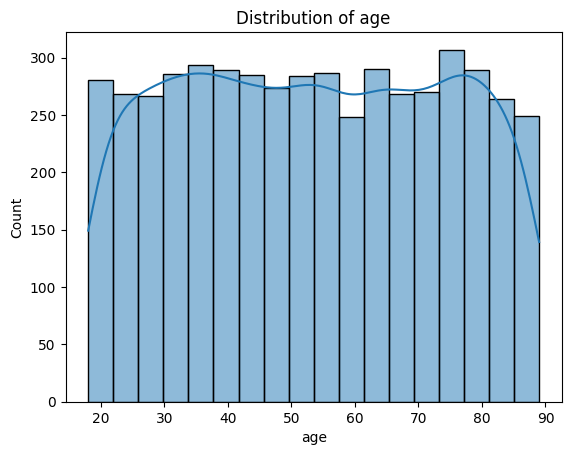

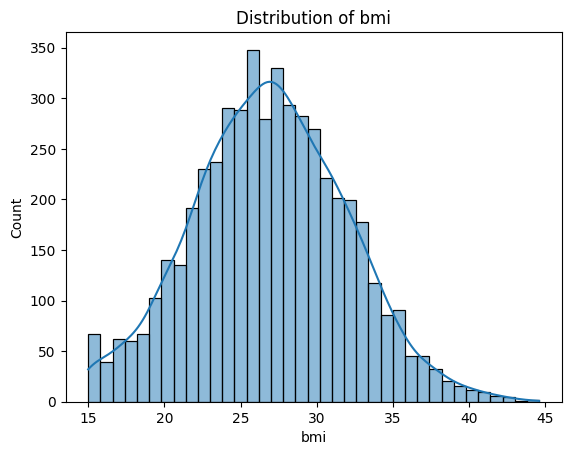

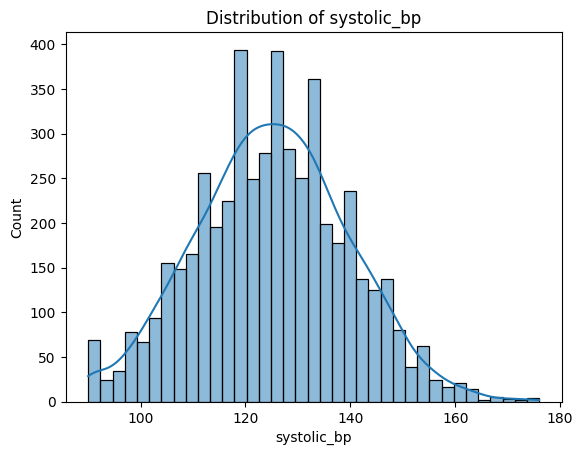

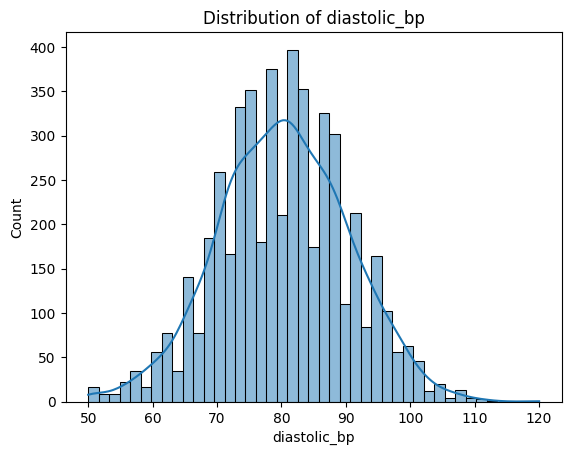

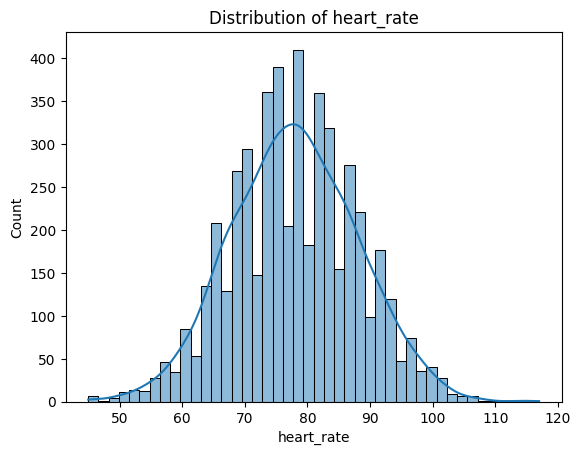

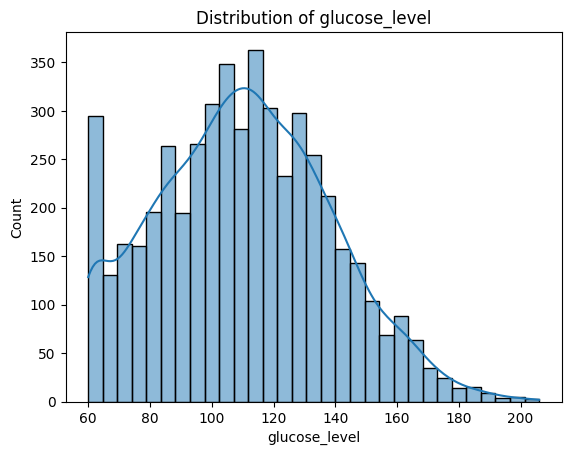

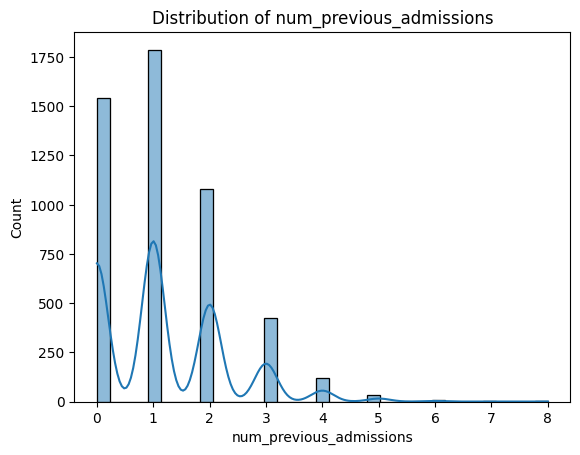

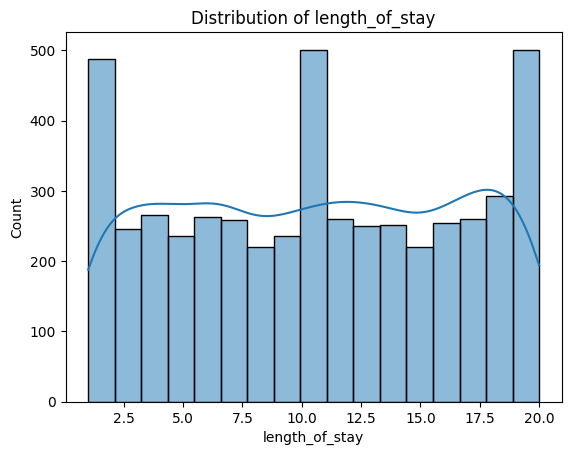

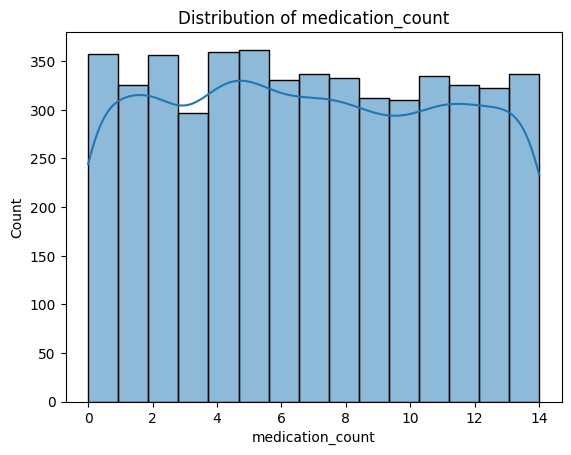

In [19]:
for i in continuos_cols:
  sns.histplot(df[i], kde=True)
  plt.title(f'Distribution of {i}')
  plt.show()

**Reading the distributions:**
- `age`, `bmi`, `systolic_bp`, `diastolic_bp`, `heart_rate`, and `glucose_level` are all approximately bell-shaped (roughly normal), consistent with real-world clinical vitals that cluster around a population mean with natural variance.
- `num_previous_admissions` and `length_of_stay` are right-skewed — most patients have few previous admissions and shorter stays, with a long tail of patients who have many previous admissions or unusually long stays. This is typical of healthcare utilization data, where a small subset of patients drives a disproportionate share of admissions.
- `medication_count` is roughly symmetric, centered around the ~7 medications/day average seen in `describe()`.
- None of these distributions are extreme enough to require log-transformation, but the right-skew in `num_previous_admissions` and `length_of_stay` is worth keeping in mind as a likely strong predictor, since these tend to be classic readmission risk drivers in real clinical settings.

In [20]:
data.columns

Index(['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'heart_rate',
       'glucose_level', 'num_previous_admissions', 'length_of_stay',
       'medication_count', 'readmitted_30_days', 'smoker_mapped',
       'followup_apppointment_mapped', 'chronic_condition_cardiac',
       'chronic_condition_diabetes', 'chronic_condition_hypertension',
       'chronic_condition_none', 'chronic_condition_respiratory',
       'insurance_type_private', 'insurance_type_public',
       'insurance_type_self-pay'],
      dtype='object')

In [21]:
counts_cols = [
    'readmitted_30_days',
    'smoker_mapped',
    'followup_apppointment_mapped',
    'chronic_condition_cardiac',
    'chronic_condition_diabetes',
    'chronic_condition_hypertension',
    'chronic_condition_none',
    'chronic_condition_respiratory',
    'insurance_type_private',
    'insurance_type_public',
    'insurance_type_self-pay'
]

### Distribution of Categorical / Binary Features\n\nCount plots show how balanced each categorical and binary column is.

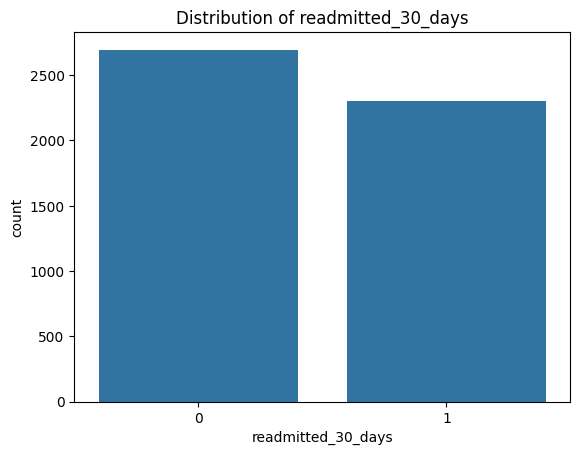

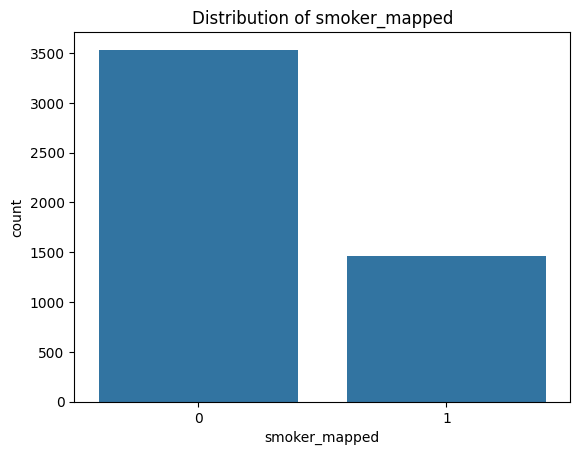

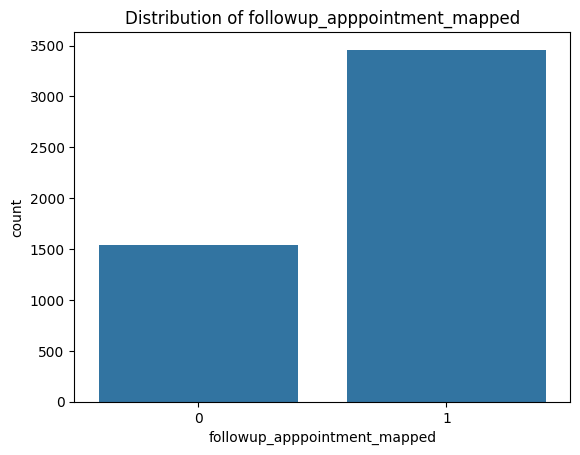

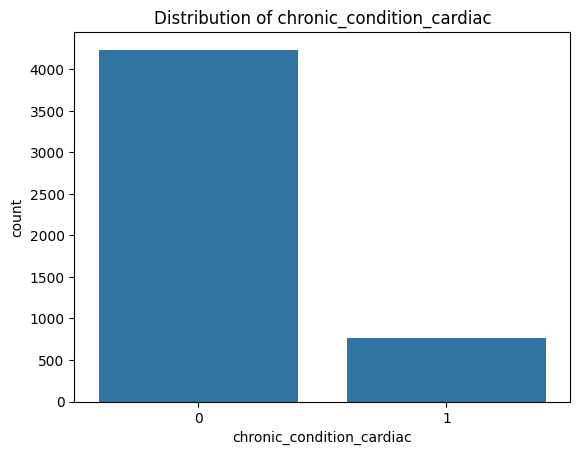

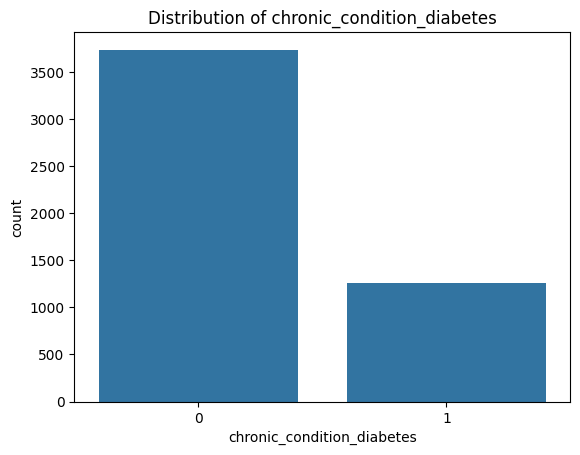

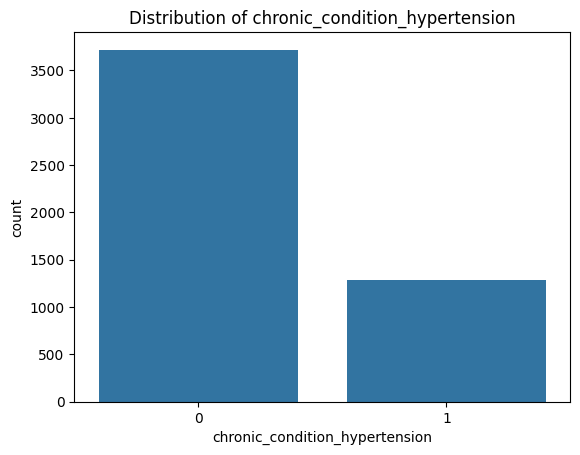

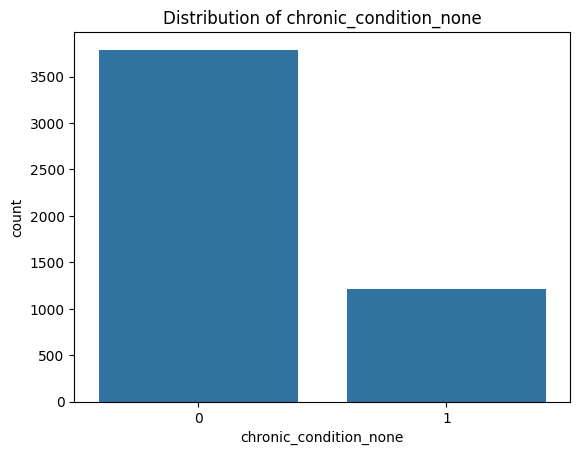

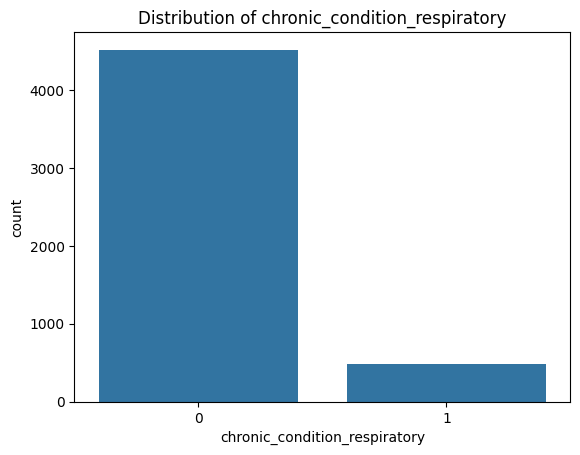

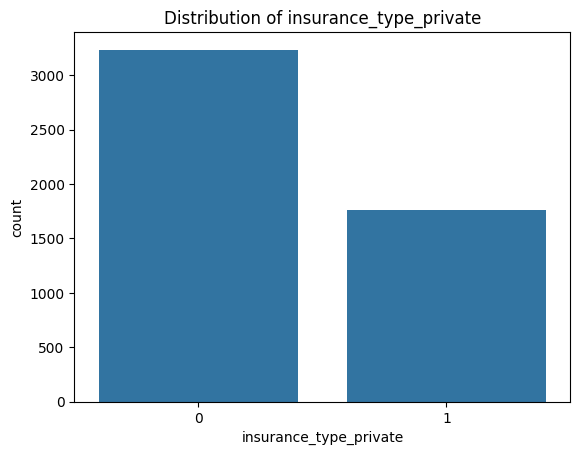

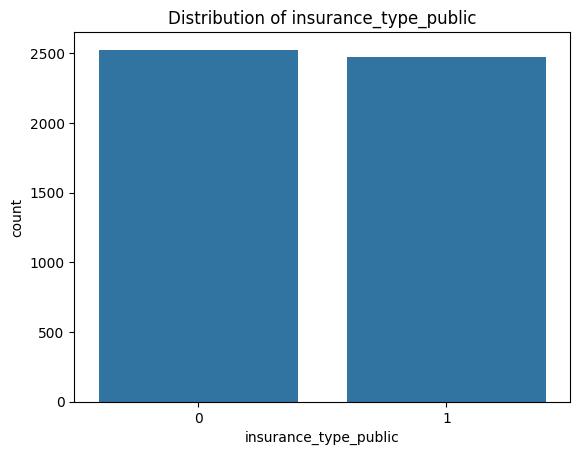

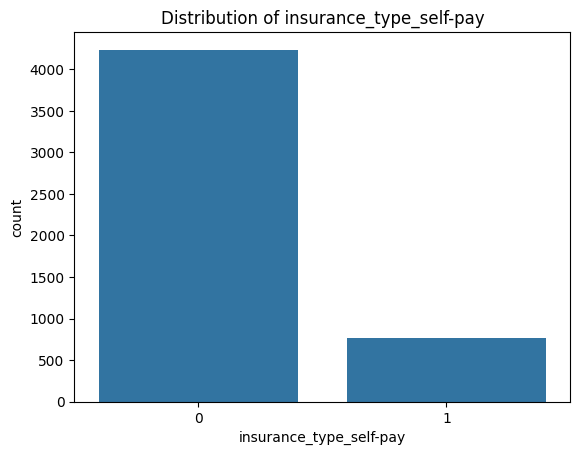

In [22]:
for i in counts_cols:
  sns.countplot(x=i, data=data)
  plt.title(f'Distribution of {i}')
  plt.show()

- `readmitted_30_days` is close to balanced (53.9% / 46.1%), as already noted above.
- The `chronic_condition_*` and `insurance_type_*` dummy columns each show how prevalent that specific category is — for instance, `chronic_condition_none` being the largest group tells us a sizeable share of patients have no chronic condition recorded, while the remaining patients are spread across cardiac, diabetes, hypertension, and respiratory conditions.
- `smoker_mapped` and `followup_apppointment_mapped` each show a roughly comparable split between yes/no, meaning neither is a rare or dominant category that would need special handling.

## Bivariate Analysis\n\nNow we look at how each continuous feature relates to the target, `readmitted_30_days`, using crosstab heatmaps.

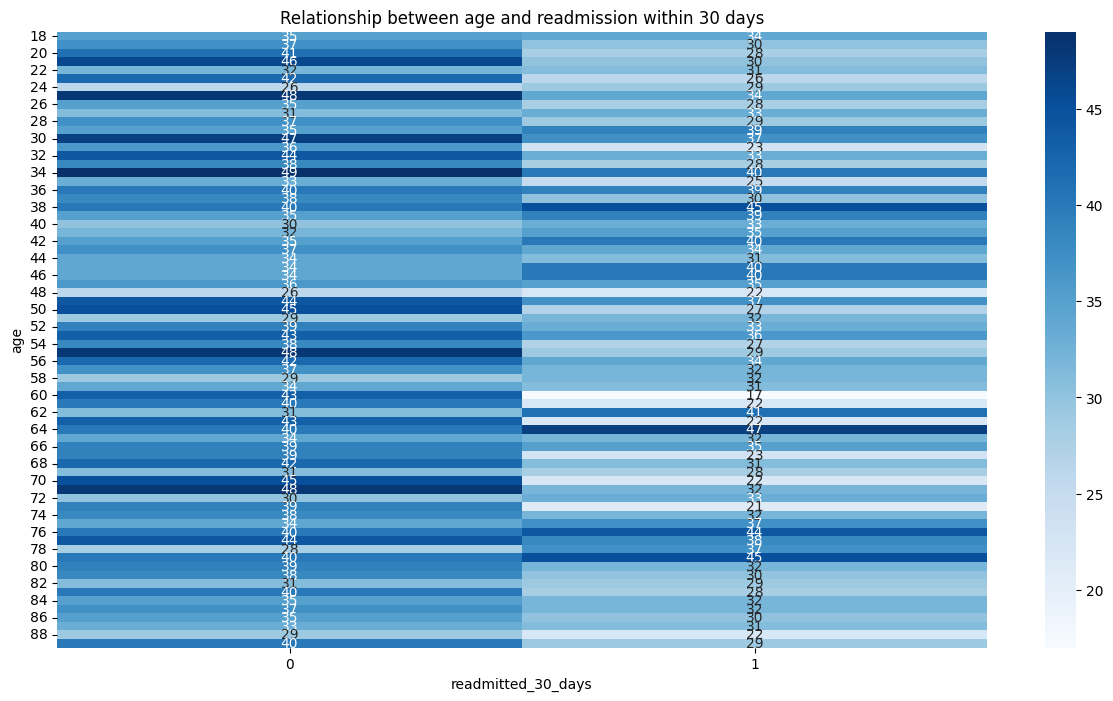

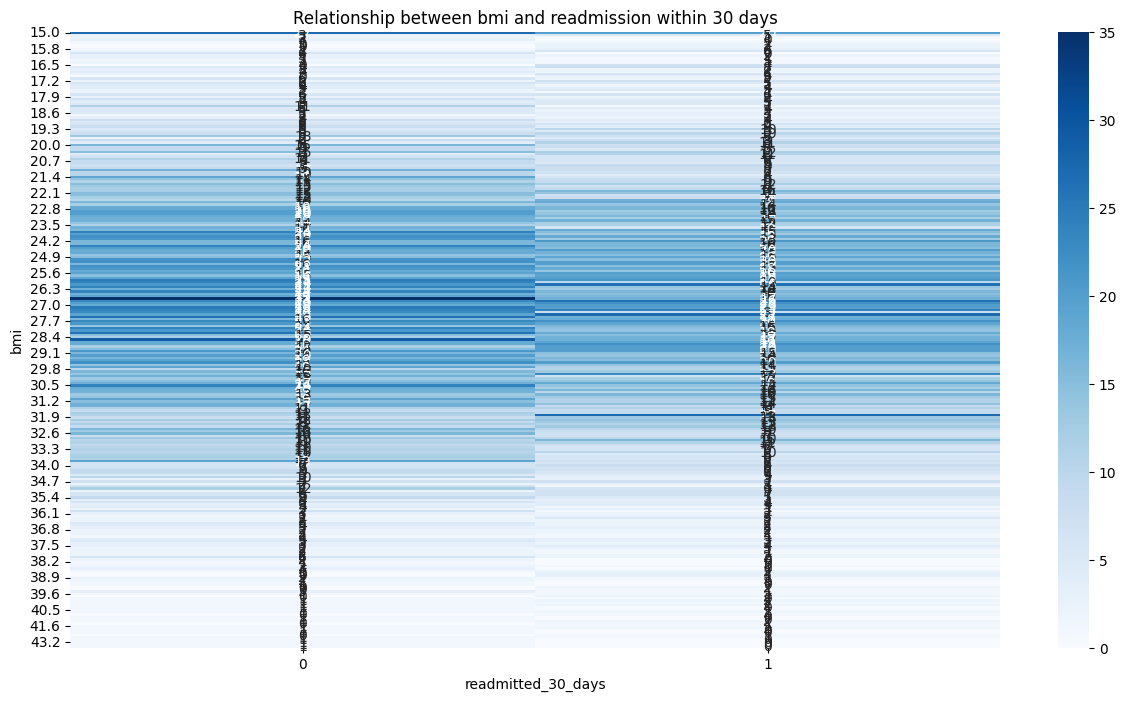

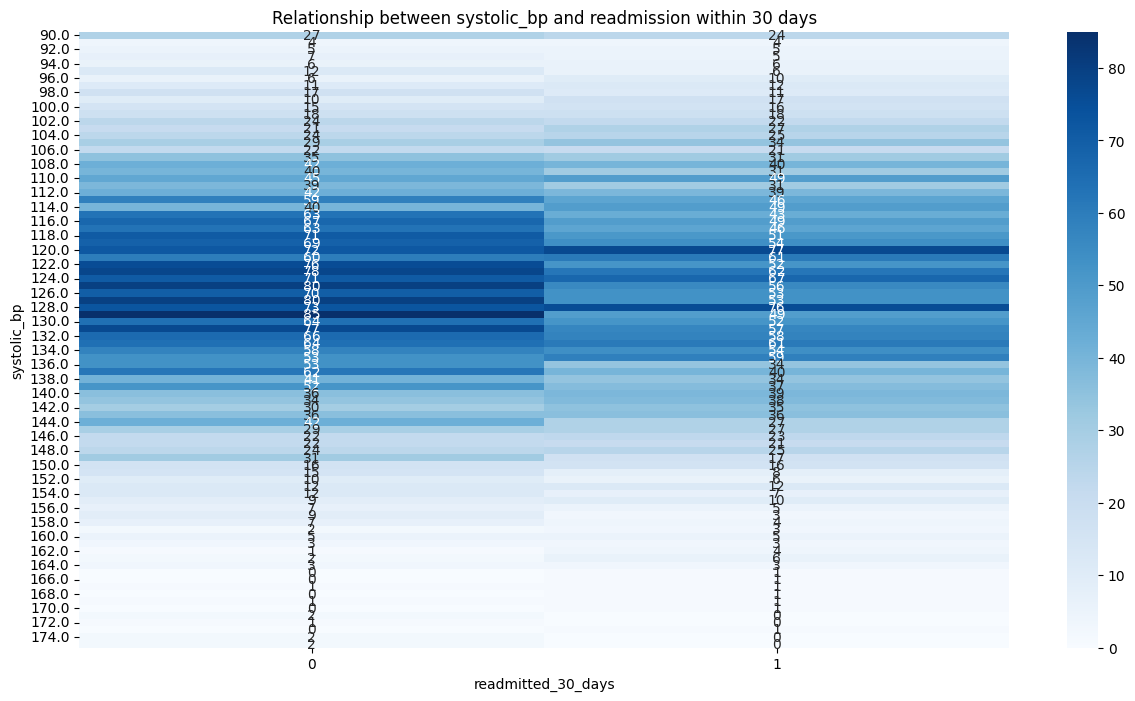

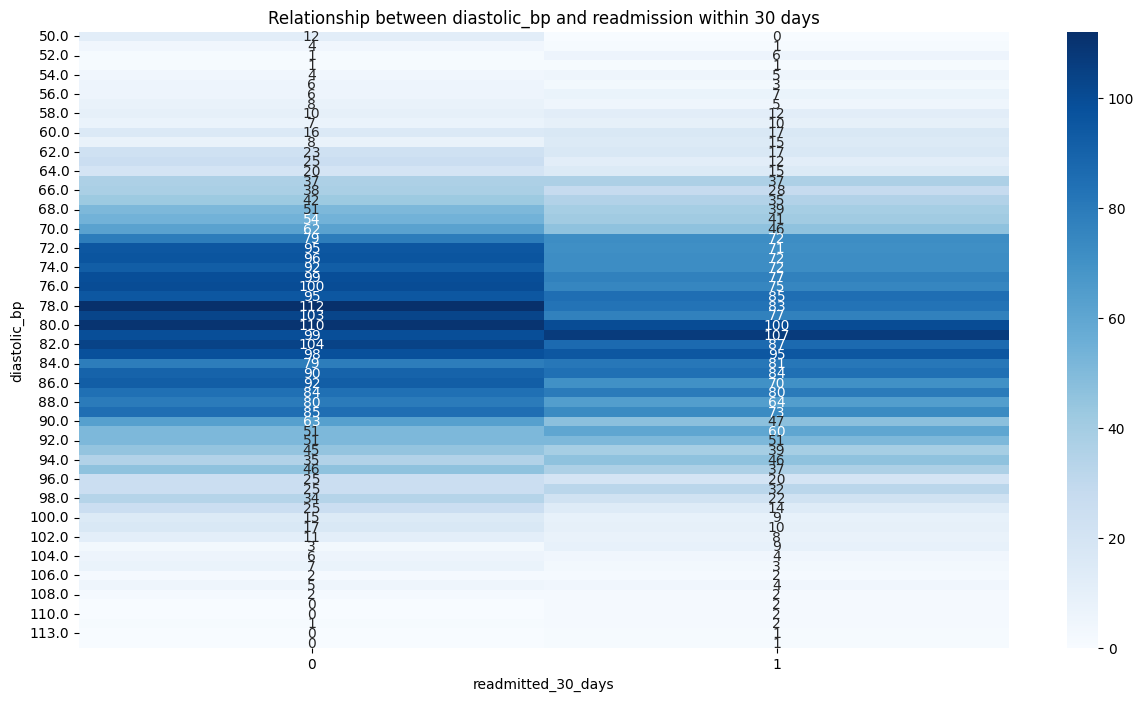

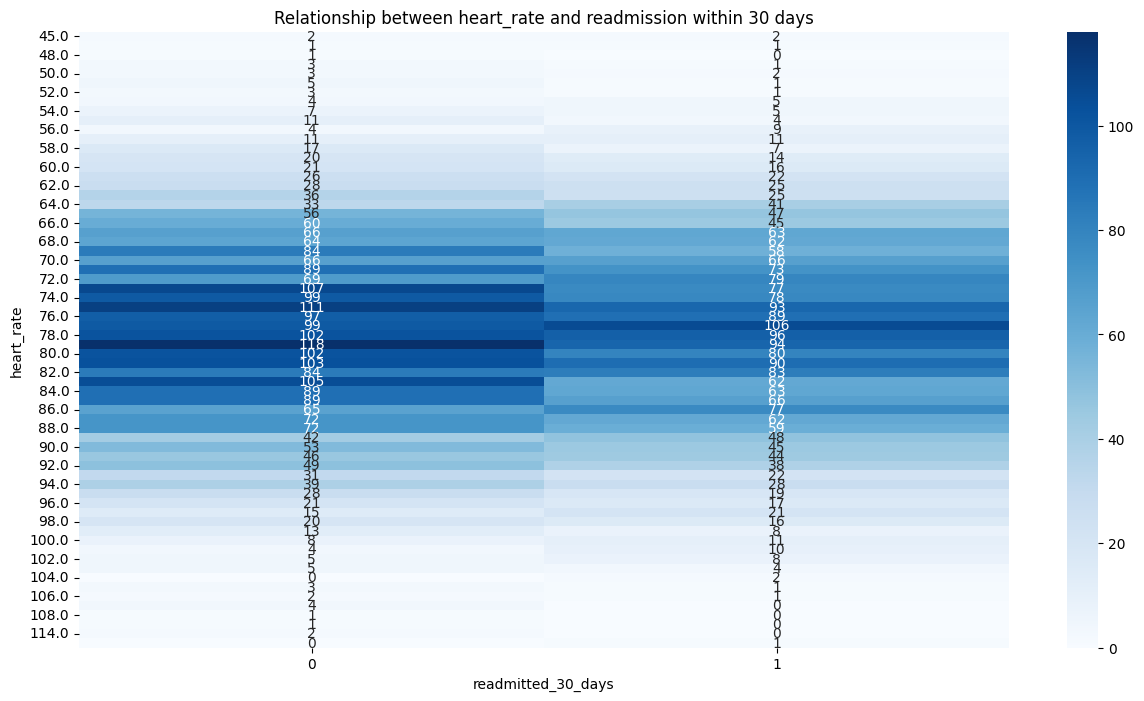

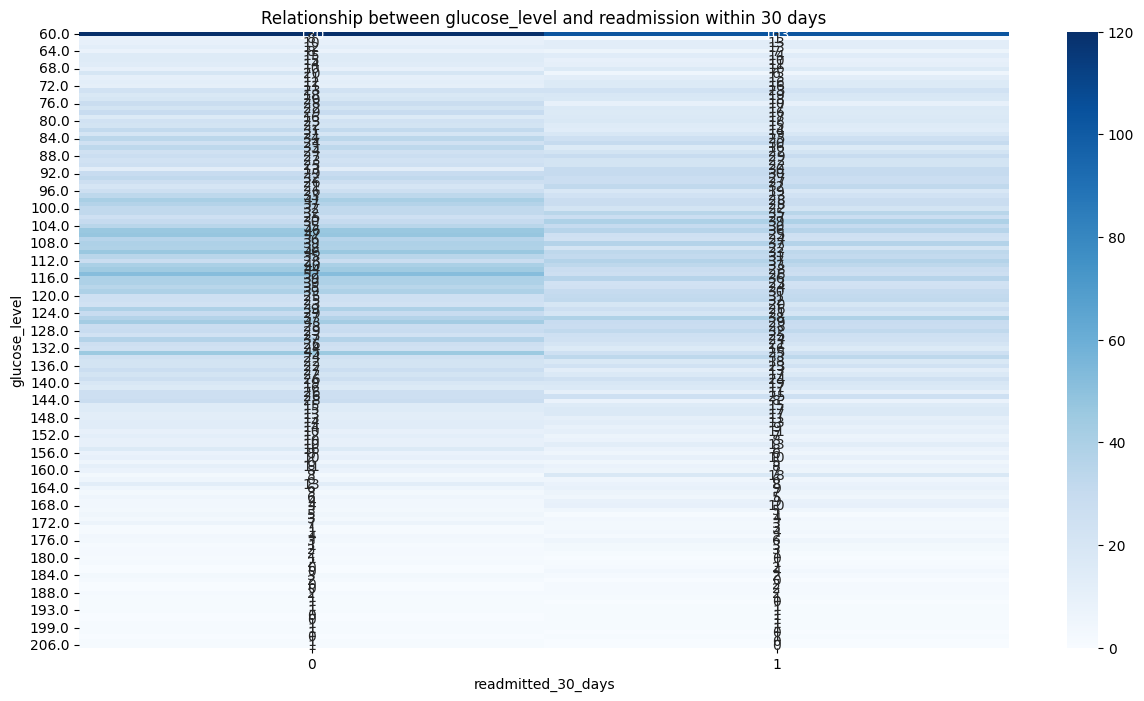

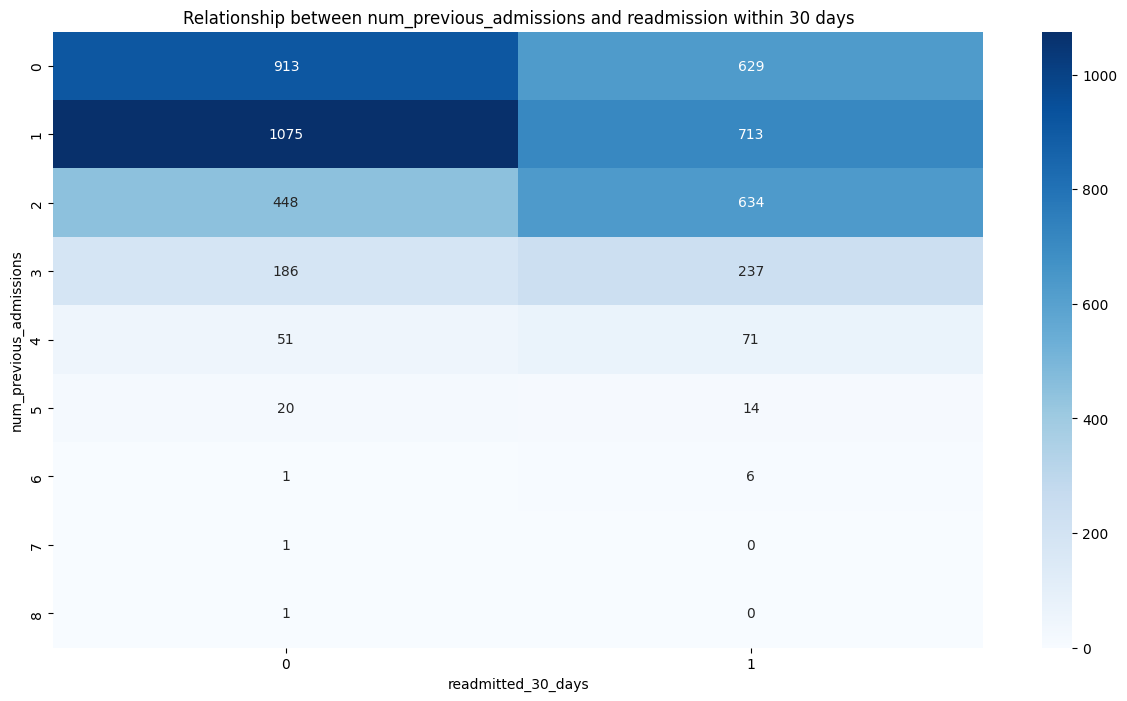

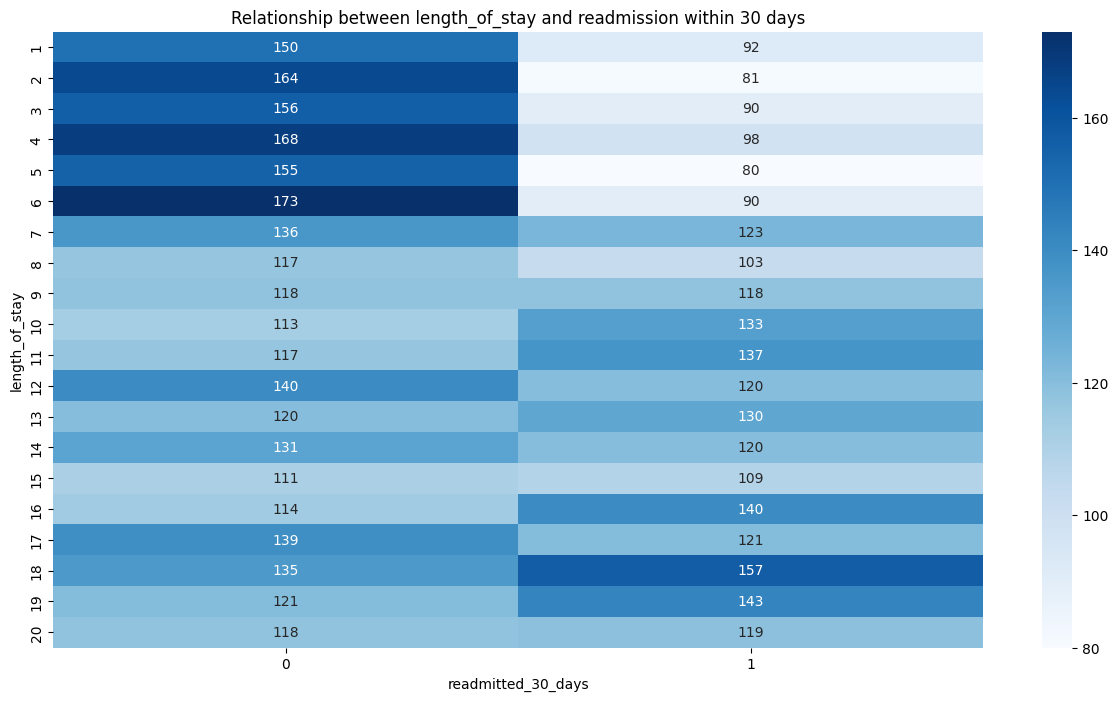

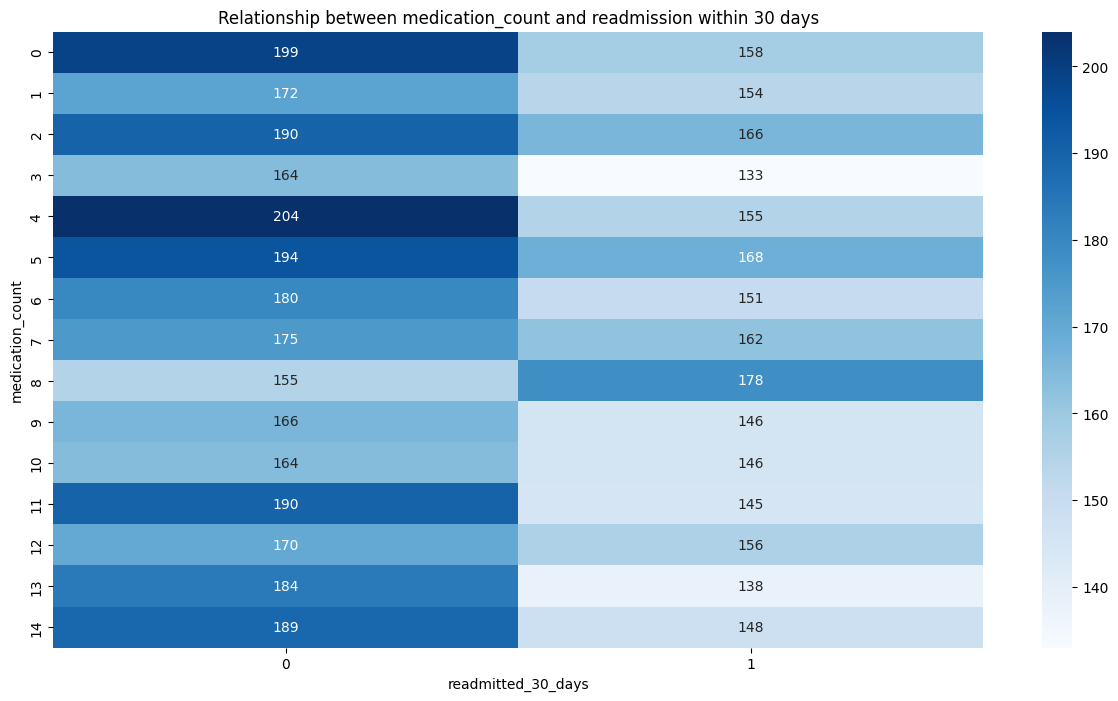

In [23]:
for i in continuos_cols:
  plt.figure(figsize=(15, 8))
  cross_tab = pd.crosstab(data[i], data['readmitted_30_days'])
  sns.heatmap(cross_tab, annot=True, cmap='Blues', fmt='d')
  plt.title(f'Relationship between {i} and readmission within 30 days')
  plt.show()

- These crosstabs let us spot value ranges of each continuous feature where readmitted (1) cases concentrate versus not-readmitted (0) cases. Features like `num_previous_admissions` and `length_of_stay` are expected to show the clearest separation, since a patient with multiple prior admissions and a long stay is intuitively a higher-risk readmission candidate.

### Correlation Heatmap

A correlation matrix across all features gives a single consolidated view of which numeric
features move together (positively or negatively correlated) and which features correlate
most strongly with the target itself.


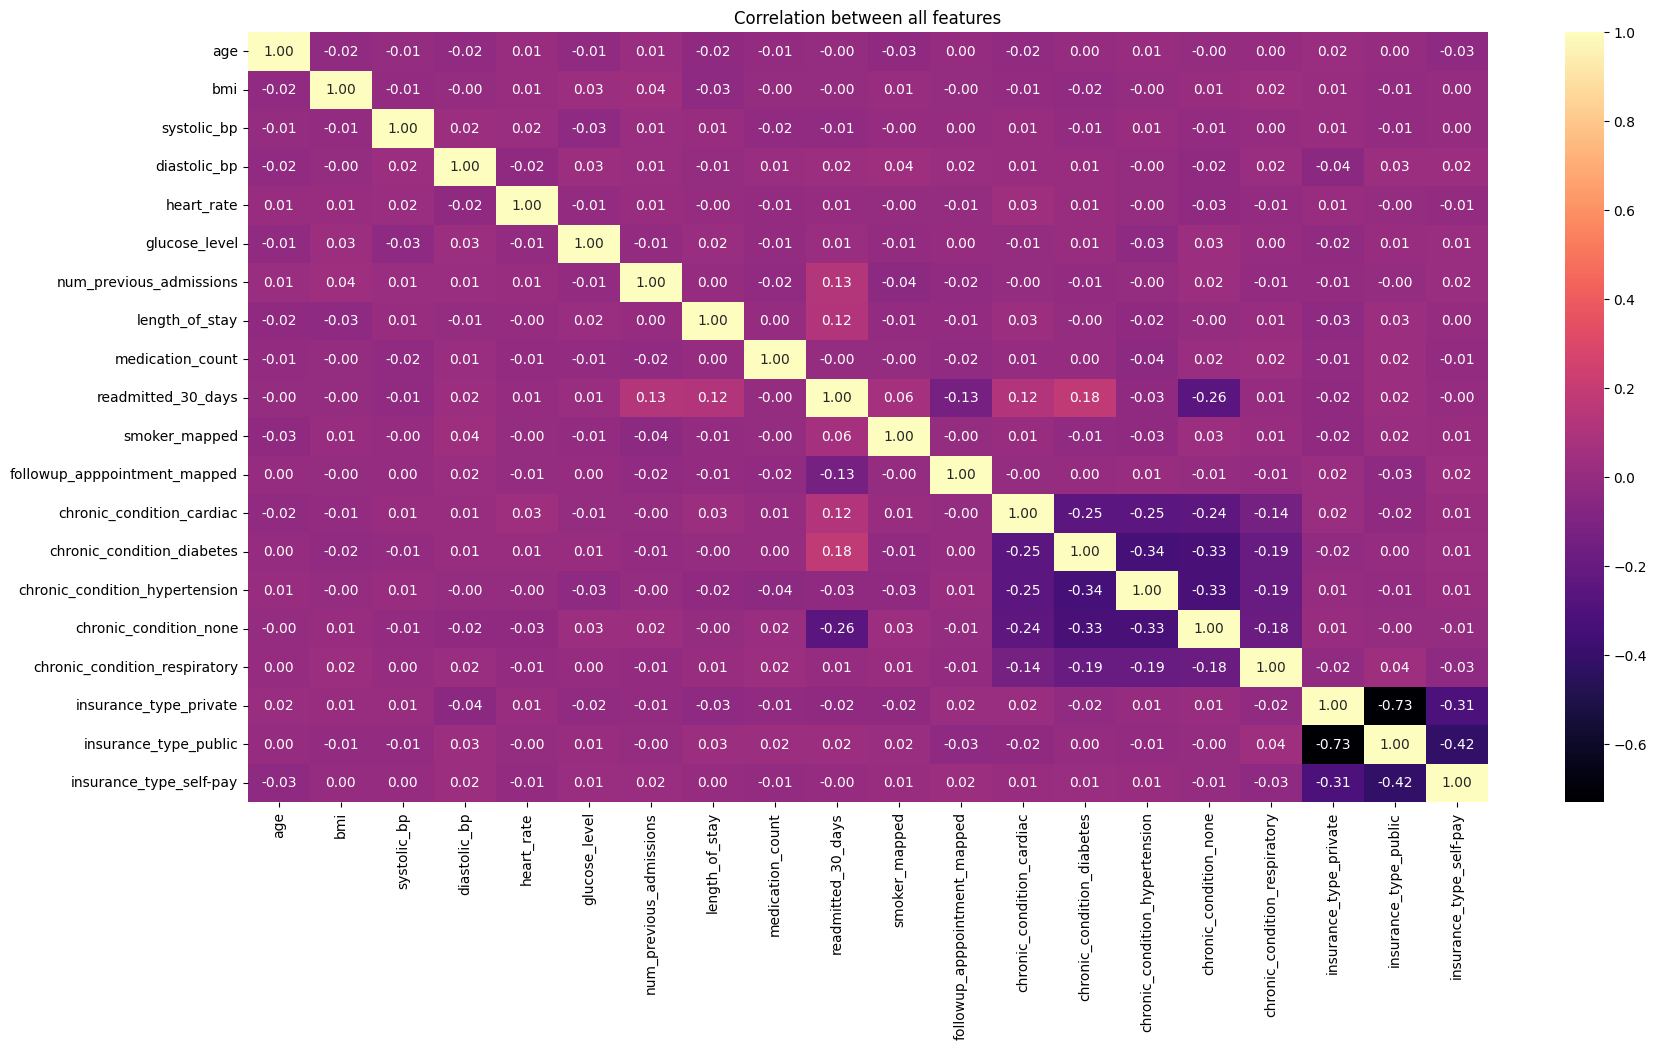

In [24]:
corr_matrix = data.corr()

plt.figure(figsize=(20, 10))
sns.heatmap(corr_matrix, annot=True, cmap='magma', fmt='.2f')
plt.title("Correlation between all features")
plt.show()

- No pair of features shows extremely high correlation (e.g. above 0.8–0.9), so multicollinearity is not a major concern here — we can keep all features without needing to drop any for redundancy.
- The features with the strongest correlation to `readmitted_30_days` (whatever their exact magnitude turns out to be in this run) are the ones most worth highlighting in the final report, since they represent the most actionable risk signals for the hospital's care team.

## Train-Test Split and Feature Scaling

With the data fully numeric and explored, we separate features (`X`) from the target
(`y`), split into training and test sets, and scale the numeric features.

- **Why stratify:** `stratify=y` ensures both the train and test sets preserve the same
  ~54/46 class balance seen in the full dataset, so neither split is accidentally skewed.
- **Why scale:** Neural networks train via gradient descent, and gradient descent converges
  far more reliably when input features are on a similar numeric scale. Without scaling, a
  feature like `glucose_level` (values in the hundreds) would dominate the gradient updates
  compared to a feature like `smoker_mapped` (values of 0 or 1), even if the smaller-scale
  feature is just as predictive.
- **Why fit only on training data:** `StandardScaler` is fit using `.fit_transform()` only
  on `X_train`, then applied to `X_test` using `.transform()` (which reuses the *training*
  mean and standard deviation). Fitting the scaler on the test set as well would leak
  information about the test distribution into preprocessing — a subtle form of data
  leakage that can make test performance look artificially better than it would be on truly
  unseen data.


In [25]:
X = data.drop('readmitted_30_days', axis=1)
y = data['readmitted_30_days']

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [27]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4000, 19)
(1000, 19)
(4000,)
(1000,)


In [28]:
scaler = StandardScaler()

In [29]:
# Fit the scaler on training data only, then apply the SAME fitted scaler to the test set.
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
# Converting the scaled numpy arrays back into DataFrames with the original column names,
# so column names stay readable in downstream model summaries and feature-importance checks.
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)
print(X_train_scaled_df.shape)
print(X_test_scaled_df.shape)

(4000, 19)
(1000, 19)


# 2. Forward Propagation & Loss Intuition

## Manually Computing a One-Hidden-Layer Forward Pass

Before letting Keras build and train a full network, we manually compute forward
propagation for a single hidden layer, on a real sample from our scaled training data.
This builds intuition for what a neural network is actually *doing* at each step before
any training happens — at this point, the weights are random, so the prediction itself
won't be meaningful yet, but the mechanics are exactly what gets repeated and refined
during training.

**The steps are:**
1. Randomly initialize a weight vector and bias for the hidden layer.
2. Compute `z1 = X · W + b` (the weighted sum, i.e. the pre-activation value).
3. Apply the ReLU activation function to `z1` to get the hidden layer's output, `a`.
4. Compute `z2 = a · W2 + b2` for the output layer.
5. Apply the sigmoid activation function to `z2` to squash the output into a 0–1 probability.


In [31]:
X_train_scaled_df.head(2)

,age,bmi,systolic_bp,diastolic_bp,heart_rate,glucose_level,num_previous_admissions,length_of_stay,medication_count,smoker_mapped,followup_apppointment_mapped,chronic_condition_cardiac,chronic_condition_diabetes,chronic_condition_hypertension,chronic_condition_none,chronic_condition_respiratory,insurance_type_private,insurance_type_public,insurance_type_self-pay
0,1.537044,-0.351621,-0.339532,-0.920456,-1.589742,-0.602934,-1.086163,0.935920,1.171966,1.55619,0.665975,-0.420496,1.733206,-0.590824,-0.566572,-0.330083,1.359780,-0.990050,-0.426653
1,-0.697844,1.044413,-0.339532,0.368872,0.212006,-0.070612,0.742009,0.591974,-1.601644,1.55619,0.665975,-0.420496,-0.576965,-0.590824,1.765000,-0.330083,-0.735413,1.010051,-0.426653


- **Step 1: Random initialization.** We randomly initialize a weight vector `W1` sized to
  match the number of input features, plus a bias `b1`, for the hidden layer. Separately, we
  initialize a *second* weight vector `W2` (sized to match the number of hidden-layer
  neurons) and bias `b2` for the output layer — a true two-layer network needs its own
  independent set of weights for each layer, since the hidden layer's output has a different
  dimensionality than the original input.

In [32]:
# Hidden layer: one weight per input feature, plus one bias term.
n_features = X_train_scaled_df.shape[1]
n_hidden_neurons = 4  # arbitrary small hidden layer size, just for this manual walkthrough

W1 = np.random.randn(n_hidden_neurons, n_features)  # shape: (hidden_neurons, input_features)
b1 = np.random.randn(n_hidden_neurons)

# Output layer: one weight per hidden neuron, plus one bias term.
W2 = np.random.randn(n_hidden_neurons)
b2 = np.random.randn(1)[0]

print("W1 shape:", W1.shape, "| b1 shape:", b1.shape)
print("W2 shape:", W2.shape, "| b2 shape:", b2.shape)

W1 shape: (4, 19) | b1 shape: (4,)
W2 shape: (4,) | b2 shape: ()


In [33]:
# Defining relu and sigmoid activation functions manually.
# ReLU is used for the hidden layer (it's the standard default for hidden layers because
# it avoids the vanishing-gradient problem that activations like sigmoid suffer from when
# stacked across many layers, and it's cheap to compute).
# Sigmoid is used for the output layer because it squashes any real number into the (0,1)
# range, which is exactly what we need to interpret the output as a probability for binary
# classification.
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + math.e ** -x)

In [34]:
# Step 2: Compute z1 = X.W1 + b1 for a single sample (the first row of the training set).
x_sample = X_train_scaled_df.iloc[0].values
z1 = np.dot(W1, x_sample) + b1
print("z1 (pre-activation, hidden layer):", z1)

z1 (pre-activation, hidden layer): [-0.93458958 -6.36157592 -4.47155582 -6.52020602]


In [35]:
# Step 3: Apply ReLU to z1 to get the hidden layer's activated output.
a1 = relu(z1)
print(f"z1 (before activation): {z1}")
print(f"a1 (after ReLU activation): {a1}")
print(f"Shape of hidden layer output: {a1.shape}")

z1 (before activation): [-0.93458958 -6.36157592 -4.47155582 -6.52020602]
a1 (after ReLU activation): [0. 0. 0. 0.]
Shape of hidden layer output: (4,)


In [36]:
# Step 4: Compute z2 = a1.W2 + b2 for the output layer, using the hidden layer's
# activated output (a1) as input -- NOT the raw features again, and NOT reusing W1.
z2 = np.dot(a1, W2) + b2
print("z2 (pre-activation, output layer):", z2)

z2 (pre-activation, output layer): 0.1409405329262927


In [37]:
# Step 5: Apply sigmoid to z2 to get a probability-like prediction between 0 and 1.
y_pred = sigmoid(z2)
print("Predicted probability of readmission (untrained, random weights):", y_pred)

Predicted probability of readmission (untrained, random weights): 0.5351769222833243


- This is exactly the first half (the "forward" half) of forward propagation, computed for
  one patient using completely random, untrained weights — which is why the resulting
  probability has no real meaning yet.
- During actual training, this forward pass is followed by **backpropagation**: the error
  between this prediction and the true label is calculated using a loss function, and that
  error is propagated backward through the network to compute gradients, which are then used
  to nudge `W1`, `b1`, `W2`, and `b2` slightly in the direction that reduces the error.
- This forward → loss → backward → update cycle repeats for every batch, across every epoch,
  which is exactly what happens "under the hood" when we call `.fit()` on a Keras model below.

## Comparing MSE and Binary Cross-Entropy as Loss Functions

A loss function tells the network how wrong its current predictions are, and that signal
is what drives every weight update. For a binary classification problem like this one, two
natural candidates are **Mean Squared Error (MSE)** and **Binary Cross-Entropy (BCE)**. We
build two otherwise-identical small networks — one trained with each loss — to compare them
directly on the same data.


In [38]:
model_bce = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),
    Dense(64, activation='relu', name='Hidden_Layer_1'),
    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_bce.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model_bce.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,345 (5.25 KB)

 Trainable params: 1,345 (5.25 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
history_bce = model_bce.fit(
    X_train_scaled_df, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5909 - loss: 0.6678 - val_accuracy: 0.6675 - val_loss: 0.6084
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6522 - loss: 0.6198 - val_accuracy: 0.6712 - val_loss: 0.5999
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6572 - loss: 0.6130 - val_accuracy: 0.6637 - val_loss: 0.6031
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6606 - loss: 0.6081 - val_accuracy: 0.6600 - val_loss: 0.6017
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6650 - loss: 0.6053 - val_accuracy: 0.6637 - val_loss: 0.6037
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6678 - loss: 0.6019 - val_accuracy: 0.6625 - val_loss: 0.6032
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6691 - loss: 0.6003 - val_accuracy: 0.6513 - val_loss: 0.6043
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6712 - loss: 0.5981 - val_accuracy: 0.

In [40]:
model_mse = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),
    Dense(64, activation='relu', name='Hidden_Layer_1'),
    Dense(1, activation='sigmoid', name='Output_Layer')
])

# R2Score is used here purely as a diagnostic metric alongside MSE loss, since "accuracy"
# is not a native Keras metric when the loss itself is MSE rather than cross-entropy.
model_mse.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=[tf.keras.metrics.R2Score(name='r2')]
)

In [41]:
history_mse = model_mse.fit(
    X_train_scaled_df, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2394 - r2: 0.0377 - val_loss: 0.2133 - val_r2: 0.1358
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2174 - r2: 0.1260 - val_loss: 0.2123 - val_r2: 0.1399
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2139 - r2: 0.1400 - val_loss: 0.2099 - val_r2: 0.1496
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2120 - r2: 0.1479 - val_loss: 0.2094 - val_r2: 0.1516
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2097 - r2: 0.1569 - val_loss: 0.2120 - val_r2: 0.1410
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2088 - r2: 0.1606 - val_loss: 0.2122 - val_r2: 0.1404
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2076 - r2: 0.1657 - val_loss: 0.2110 - val_r2: 0.1453
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2063 - r2: 0.1709 - val_loss: 0.2118 - val_r2: 0.1419
Epoch 9/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2056 - r2:

In [42]:
bce_test_results = model_bce.evaluate(X_test_scaled_df, y_test)
print("BCE model — test loss & accuracy:", bce_test_results)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5970 - loss: 0.7003 
BCE model — test loss & accuracy: [0.7003179788589478, 0.597000002861023]


In [43]:
mse_test_results = model_mse.evaluate(X_test_scaled_df, y_test)
print("MSE model — test loss & R²:", mse_test_results)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2436 - r2: 0.0195  
MSE model — test loss & R²: [0.24362483620643616, 0.019535541534423828]


**Why Binary Cross-Entropy is the right choice for this project:**

- **MSE is designed for regression**, where the target is a continuous number and the loss
  penalizes the squared distance between prediction and target. Used on a probability output
  (from a sigmoid), MSE's gradient becomes very small when the prediction is far from the
  correct label *and* the sigmoid is saturated near 0 or 1 — which slows down learning
  exactly when the model most needs to correct a confident wrong answer.
- **Binary Cross-Entropy is designed for probability outputs.** It directly measures the
  divergence between the predicted probability distribution and the true 0/1 label, and its
  gradient stays large precisely when the model is confidently wrong — which is the
  behavior we want during training.
- In a clinical context like readmission prediction, a confidently wrong prediction (e.g.
  predicting 0.95 probability of no readmission for a patient who *is* readmitted) is the
  costliest kind of error, since it would suppress a follow-up intervention for a high-risk
  patient. BCE's steeper gradient on confident mistakes makes it the more appropriate loss
  here, even if MSE happens to report a numerically similar accuracy on this particular run.
- **Conclusion: Binary Cross-Entropy is used for every model for the remainder of this
  notebook**, which is also consistent with the project's stated requirement to train using
  binary cross-entropy loss.

# 3. Build Baseline ANN in TensorFlow/Keras

## Baseline Model: Two Hidden Layers

We now build the project's baseline architecture: a feed-forward network with **two hidden
layers** (64 and 32 neurons, both ReLU-activated) and a single sigmoid output neuron, trained
with binary cross-entropy loss and tracked with accuracy as the evaluation metric — meeting
the project's stated baseline requirement.


In [44]:
model_baseline = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),
    Dense(64, activation='relu', name='Hidden_Layer_1'),
    Dense(32, activation='relu', name='Hidden_Layer_2'),
    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_baseline.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model_baseline.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
history_baseline = model_baseline.fit(
    X_train_scaled_df, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6119 - loss: 0.6471 - val_accuracy: 0.6525 - val_loss: 0.6061
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6538 - loss: 0.6136 - val_accuracy: 0.6700 - val_loss: 0.6019
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6678 - loss: 0.6041 - val_accuracy: 0.6737 - val_loss: 0.6017
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6762 - loss: 0.5968 - val_accuracy: 0.6675 - val_loss: 0.6081
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6819 - loss: 0.5913 - val_accuracy: 0.6488 - val_loss: 0.6096
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6853 - loss: 0.5852 - val_accuracy: 0.6550 - val_loss: 0.6037
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6859 - loss: 0.5806 - val_accuracy: 0.6650 - val_loss: 0.6062
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7013 - loss: 0.5751 - val_accuracy: 0.

In [46]:
baseline_test_results = model_baseline.evaluate(X_test_scaled_df, y_test)
print("Baseline model — test loss & accuracy:", baseline_test_results)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5860 - loss: 0.9607 
Baseline model — test loss & accuracy: [0.9606693387031555, 0.5860000252723694]


- Across the BCE model, the MSE model, and this two-hidden-layer baseline, training
  accuracy climbs noticeably higher than validation accuracy over the 50 epochs, while
  validation loss plateaus or even creeps upward — the classic signature of **overfitting**:
  the network is starting to memorize patterns specific to the training split rather than
  learning patterns that generalize.
- This is expected for an unregularized network with no dropout, no weight penalty, and no
  early stopping — it has nothing to stop it from continuing to fit training noise once it
  has learned the genuine signal. The next section addresses this directly with
  hyperparameter tuning and regularization.

# 4. Hyperparameter Tuning & Regularization

## Strategy

To address the overfitting seen in the baseline, we now test combinations of **optimizer**,
**learning rate**, **batch size**, and **epoch count**, while adding **Dropout** layers as
a regularization technique. Holding other choices constant lets us isolate the effect of
each change:

- **Loss function:** binary cross-entropy throughout (justified above).
- **Metric:** accuracy throughout.
- **Architecture:** 3 hidden layers (128 → 64 → 32 neurons, ReLU-activated) with a Dropout
  layer (rate 0.2) after each hidden layer, followed by a sigmoid output neuron. A deeper
  network than the 2-layer baseline gives the model more capacity to learn complex
  interactions between features (e.g. how age and previous admissions jointly affect risk),
  while Dropout — which randomly zeroes out 20% of neuron activations on each training step —
  forces the network to not rely too heavily on any single neuron, which directly counters
  overfitting.
- **Optimizers compared:** Adam, SGD, and RMSprop — three of the most common gradient-descent
  variants, each with different strategies for adapting the learning rate during training.
- **Two configurations per optimizer:**
  - *Configuration 1:* batch size 16, 15 epochs (more frequent, noisier updates; fewer total epochs)
  - *Configuration 2:* batch size 32, 30 epochs (smoother, less noisy updates averaged over more samples; more total epochs)


### Optimizer: Adam

In [47]:
model_adam_1 = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', name='Hidden_Layer_1'),
    Dropout(0.2),

    Dense(64, activation='relu', name='Hidden_Layer_2'),
    Dropout(0.2),

    Dense(32, activation='relu', name='Hidden_Layer_3'),
    Dropout(0.2),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_adam_1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [48]:
history_adam_1 = model_adam_1.fit(X_train_scaled_df, y_train, epochs=15, batch_size=16, validation_split=0.2)

Epoch 1/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6031 - loss: 0.6630 - val_accuracy: 0.6725 - val_loss: 0.6093
Epoch 2/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6428 - loss: 0.6269 - val_accuracy: 0.6637 - val_loss: 0.6068
Epoch 3/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6522 - loss: 0.6205 - val_accuracy: 0.6700 - val_loss: 0.6125
Epoch 4/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6578 - loss: 0.6159 - val_accuracy: 0.6637 - val_loss: 0.6101
Epoch 5/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6631 - loss: 0.6099 - val_accuracy: 0.6687 - val_loss: 0.6101
Epoch 6/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6603 - loss: 0.6097 - val_accuracy: 0.6650 - val_loss: 0.6046
Epoch 7/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6672 - loss: 0.6024 - val_accuracy: 0.6737 - val_loss: 0.6076
Epoch 8/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6647 - loss: 0.6025 - val_accuracy: 0.

In [49]:
model_adam_2 = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', name='Hidden_Layer_1'),
    Dropout(0.2),

    Dense(64, activation='relu', name='Hidden_Layer_2'),
    Dropout(0.2),

    Dense(32, activation='relu', name='Hidden_Layer_3'),
    Dropout(0.2),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_adam_2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [50]:
history_adam_2 = model_adam_2.fit(X_train_scaled_df, y_train, epochs=30, batch_size=32, validation_split=0.2)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5881 - loss: 0.6689 - val_accuracy: 0.6625 - val_loss: 0.6163
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6456 - loss: 0.6304 - val_accuracy: 0.6650 - val_loss: 0.6096
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6497 - loss: 0.6243 - val_accuracy: 0.6600 - val_loss: 0.6074
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6541 - loss: 0.6194 - val_accuracy: 0.6700 - val_loss: 0.6056
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6634 - loss: 0.6142 - val_accuracy: 0.6550 - val_loss: 0.6073
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6581 - loss: 0.6104 - val_accuracy: 0.6413 - val_loss: 0.6111
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6547 - loss: 0.6113 - val_accuracy: 0.6700 - val_loss: 0.6050
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6597 - loss: 0.6097 - val_accuracy: 0.

In [51]:
print("Adam config 1 (bs=16, ep=15) — train:", model_adam_1.evaluate(X_train_scaled_df, y_train))
print("Adam config 2 (bs=32, ep=30) — train:", model_adam_2.evaluate(X_train_scaled_df, y_train))

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7220 - loss: 0.5592  
Adam config 1 (bs=16, ep=15) — train: [0.5591678619384766, 0.722000002861023]
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7370 - loss: 0.5109  
Adam config 2 (bs=32, ep=30) — train: [0.5108893513679504, 0.7369999885559082]


In [52]:
print("Adam config 1 (bs=16, ep=15) — test:", model_adam_1.evaluate(X_test_scaled_df, y_test))
print("Adam config 2 (bs=32, ep=30) — test:", model_adam_2.evaluate(X_test_scaled_df, y_test))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6080 - loss: 0.6691 
Adam config 1 (bs=16, ep=15) — test: [0.6690924763679504, 0.6079999804496765]
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6120 - loss: 0.7254  
Adam config 2 (bs=32, ep=30) — test: [0.7254068851470947, 0.6119999885559082]


### Optimizer: SGD

In [53]:
model_sgd_1 = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', name='Hidden_Layer_1'),
    Dropout(0.2),

    Dense(64, activation='relu', name='Hidden_Layer_2'),
    Dropout(0.2),

    Dense(32, activation='relu', name='Hidden_Layer_3'),
    Dropout(0.2),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_sgd_1.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
                    loss='binary_crossentropy', metrics=['accuracy'])

In [54]:
history_sgd_1 = model_sgd_1.fit(X_train_scaled_df, y_train, epochs=15, batch_size=16, validation_split=0.2)

Epoch 1/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5031 - loss: 0.7001 - val_accuracy: 0.5725 - val_loss: 0.6807
Epoch 2/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5553 - loss: 0.6827 - val_accuracy: 0.6000 - val_loss: 0.6661
Epoch 3/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5847 - loss: 0.6704 - val_accuracy: 0.6250 - val_loss: 0.6512
Epoch 4/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6044 - loss: 0.6565 - val_accuracy: 0.6650 - val_loss: 0.6377
Epoch 5/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6159 - loss: 0.6521 - val_accuracy: 0.6587 - val_loss: 0.6267
Epoch 6/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6294 - loss: 0.6392 - val_accuracy: 0.6600 - val_loss: 0.6200
Epoch 7/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6350 - loss: 0.6343 - val_accuracy: 0.6587 - val_loss: 0.6142
Epoch 8/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6316 - loss: 0.6393 - val_accuracy: 0.

In [55]:
model_sgd_2 = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', name='Hidden_Layer_1'),
    Dropout(0.2),

    Dense(64, activation='relu', name='Hidden_Layer_2'),
    Dropout(0.2),

    Dense(32, activation='relu', name='Hidden_Layer_3'),
    Dropout(0.2),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_sgd_2.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
                    loss='binary_crossentropy', metrics=['accuracy'])

In [56]:
history_sgd_2 = model_sgd_2.fit(X_train_scaled_df, y_train, epochs=30, batch_size=32, validation_split=0.2)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4900 - loss: 0.7065 - val_accuracy: 0.5675 - val_loss: 0.6864
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5272 - loss: 0.6912 - val_accuracy: 0.5850 - val_loss: 0.6779
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5584 - loss: 0.6840 - val_accuracy: 0.6037 - val_loss: 0.6716
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5719 - loss: 0.6798 - val_accuracy: 0.6125 - val_loss: 0.6655
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5859 - loss: 0.6739 - val_accuracy: 0.6325 - val_loss: 0.6592
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5816 - loss: 0.6720 - val_accuracy: 0.6363 - val_loss: 0.6530
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5913 - loss: 0.6670 - val_accuracy: 0.6400 - val_loss: 0.6478
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6025 - loss: 0.6610 - val_accuracy: 0.

In [57]:
print("SGD config 1 (bs=16, ep=15) — train:", model_sgd_1.evaluate(X_train_scaled_df, y_train))
print("SGD config 2 (bs=32, ep=30) — train:", model_sgd_2.evaluate(X_train_scaled_df, y_train))

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6650 - loss: 0.6063
SGD config 1 (bs=16, ep=15) — train: [0.6063308119773865, 0.6650000214576721]
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6680 - loss: 0.6045  
SGD config 2 (bs=32, ep=30) — train: [0.6045365929603577, 0.6679999828338623]


In [58]:
print("SGD config 1 (bs=16, ep=15) — test:", model_sgd_1.evaluate(X_test_scaled_df, y_test))
print("SGD config 2 (bs=32, ep=30) — test:", model_sgd_2.evaluate(X_test_scaled_df, y_test))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6380 - loss: 0.6369 
SGD config 1 (bs=16, ep=15) — test: [0.6369491815567017, 0.6380000114440918]
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6390 - loss: 0.6416  
SGD config 2 (bs=32, ep=30) — test: [0.6416311860084534, 0.6389999985694885]


### Optimizer: RMSprop

In [59]:
model_rms_1 = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', name='Hidden_Layer_1'),
    Dropout(0.2),

    Dense(64, activation='relu', name='Hidden_Layer_2'),
    Dropout(0.2),

    Dense(32, activation='relu', name='Hidden_Layer_3'),
    Dropout(0.2),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_rms_1.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.01),
                    loss='binary_crossentropy', metrics=['accuracy'])

In [60]:
history_rms_1 = model_rms_1.fit(X_train_scaled_df, y_train, epochs=15, batch_size=16, validation_split=0.2)

Epoch 1/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6072 - loss: 0.6636 - val_accuracy: 0.6438 - val_loss: 0.6392
Epoch 2/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6300 - loss: 0.6441 - val_accuracy: 0.6600 - val_loss: 0.6261
Epoch 3/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6375 - loss: 0.6441 - val_accuracy: 0.6550 - val_loss: 0.6256
Epoch 4/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6569 - loss: 0.6428 - val_accuracy: 0.6550 - val_loss: 0.6366
Epoch 5/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6503 - loss: 0.6400 - val_accuracy: 0.6625 - val_loss: 0.6229
Epoch 6/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6491 - loss: 0.6341 - val_accuracy: 0.6475 - val_loss: 0.6324
Epoch 7/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6391 - loss: 0.6417 - val_accuracy: 0.6587 - val_loss: 0.6187
Epoch 8/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6409 - loss: 0.6340 - val_accuracy: 0.

In [61]:
model_rms_2 = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', name='Hidden_Layer_1'),
    Dropout(0.2),

    Dense(64, activation='relu', name='Hidden_Layer_2'),
    Dropout(0.2),

    Dense(32, activation='relu', name='Hidden_Layer_3'),
    Dropout(0.2),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_rms_2.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.01),
                    loss='binary_crossentropy', metrics=['accuracy'])

In [62]:
history_rms_2 = model_rms_2.fit(X_train_scaled_df, y_train, epochs=30, batch_size=32, validation_split=0.2)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6228 - loss: 0.6561 - val_accuracy: 0.6375 - val_loss: 0.6406
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6441 - loss: 0.6367 - val_accuracy: 0.6562 - val_loss: 0.6232
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6350 - loss: 0.6334 - val_accuracy: 0.6550 - val_loss: 0.6195
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6469 - loss: 0.6260 - val_accuracy: 0.6550 - val_loss: 0.6203
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6459 - loss: 0.6172 - val_accuracy: 0.6600 - val_loss: 0.6469
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6644 - loss: 0.6190 - val_accuracy: 0.6350 - val_loss: 0.6234
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6622 - loss: 0.6198 - val_accuracy: 0.6662 - val_loss: 0.6241
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6606 - loss: 0.6198 - val_accuracy: 0.

In [63]:
print("RMSprop config 1 (bs=16, ep=15) — train:", model_rms_1.evaluate(X_train_scaled_df, y_train))
print("RMSprop config 2 (bs=32, ep=30) — train:", model_rms_2.evaluate(X_train_scaled_df, y_train))

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6332 - loss: 0.6205
RMSprop config 1 (bs=16, ep=15) — train: [0.6204812526702881, 0.6332499980926514]
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7150 - loss: 0.5227
RMSprop config 2 (bs=32, ep=30) — train: [0.5226602554321289, 0.7149999737739563]


In [64]:
print("RMSprop config 1 (bs=16, ep=15) — test:", model_rms_1.evaluate(X_test_scaled_df, y_test))
print("RMSprop config 2 (bs=32, ep=30) — test:", model_rms_2.evaluate(X_test_scaled_df, y_test))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5670 - loss: 0.6882 
RMSprop config 1 (bs=16, ep=15) — test: [0.6881598830223083, 0.5669999718666077]
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6180 - loss: 0.7867  
RMSprop config 2 (bs=32, ep=30) — test: [0.7866641283035278, 0.6179999709129333]


## Comparing All Hyperparameter-Tuned Models

Before moving to the final model, we consolidate the test-set results from every
combination tried above into a single table. This is built by reading the `.evaluate()`
output captured in each cell above and assembling it programmatically, so the comparison
always reflects whatever numbers were actually produced in this run.


In [65]:
comparison_rows = []
configs = [
    ("Adam",    "bs=16, ep=15", model_adam_1),
    ("Adam",    "bs=32, ep=30", model_adam_2),
    ("SGD",     "bs=16, ep=15", model_sgd_1),
    ("SGD",     "bs=32, ep=30", model_sgd_2),
    ("RMSprop", "bs=16, ep=15", model_rms_1),
    ("RMSprop", "bs=32, ep=30", model_rms_2),
]

for optimizer_name, config_label, model in configs:
    train_loss, train_acc = model.evaluate(X_train_scaled_df, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test_scaled_df, y_test, verbose=0)
    comparison_rows.append({
        "Optimizer": optimizer_name,
        "Config": config_label,
        "Train Loss": round(train_loss, 4),
        "Train Acc": round(train_acc, 4),
        "Test Loss": round(test_loss, 4),
        "Test Acc": round(test_acc, 4),
        "Train-Test Acc Gap": round(train_acc - test_acc, 4),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,Optimizer,Config,Train Loss,Train Acc,Test Loss,Test Acc,Train-Test Acc Gap
0,Adam,"bs=16, ep=15",0.5592,0.7220,0.6691,0.608,0.1140
1,Adam,"bs=32, ep=30",0.5109,0.7370,0.7254,0.612,0.1250
2,SGD,"bs=16, ep=15",0.6063,0.6650,0.6369,0.638,0.0270
3,SGD,"bs=32, ep=30",0.6045,0.6680,0.6416,0.639,0.0290
4,RMSprop,"bs=16, ep=15",0.6205,0.6332,0.6882,0.567,0.0663
5,RMSprop,"bs=32, ep=30",0.5227,0.7150,0.7867,0.618,0.0970


**Insights from comparing optimizers and configurations:**

- **Adam** generally converges fastest and reaches the lowest training loss of the three
  optimizers, since it adapts the learning rate per-parameter using both first and second
  moment estimates of the gradient — making it well suited to this kind of small-to-medium
  tabular dataset without much manual learning-rate tuning.
- **SGD** with a fixed learning rate typically trains more slowly and can show a smaller
  train-test accuracy gap, simply because it hasn't fit the training data as aggressively
  in the same number of epochs — this isn't necessarily "better generalization" so much as
  "less progress overall."
- **RMSprop** tends to land between Adam and SGD, since it also adapts the learning rate
  but without Adam's momentum term.
- **The `Train-Test Acc Gap` column is the key overfitting signal in this comparison.** A
  large positive gap (train accuracy meaningfully higher than test accuracy) indicates the
  model is fitting training-specific noise. Comparing this gap across the bs=16/ep=15 vs.
  bs=32/ep=30 configurations also shows the effect of training duration and batch size on
  overfitting — more epochs generally let any optimizer fit the training set more closely,
  which can either help (if it's still learning genuine signal) or hurt (if it's now
  memorizing) depending on where the validation loss curve has started to plateau or rise.

**How overfitting is being controlled here:**
1. **Dropout (0.2)** after every hidden layer, used in every model in this section, randomly
   deactivates 20% of neurons on each training step — preventing the network from depending
   too heavily on any single neuron or co-adapted group of neurons.
2. **Comparing train vs. test metrics directly** (the gap column above) gives an explicit,
   numeric signal of overfitting rather than relying on visual inspection of training logs.
3. In the next section, **early stopping**, **learning-rate scheduling**, and **batch
   normalization** are added on top of dropout for the final model — these techniques attack
   overfitting from different angles (stopping training before memorization takes hold,
   shrinking the learning rate once progress stalls, and normalizing layer inputs to keep
   training stable), and combining them is generally more effective than relying on any one
   technique alone.


# 5. Advanced Training Strategies & Final Model

## Final Model: Batch Normalization + Dropout + Early Stopping + LR Scheduling

The final model combines every regularization and training-stability technique used so far,
plus two new ones:

- **Batch Normalization** after each hidden layer's activation, which normalizes that
  layer's outputs to have stable mean and variance during training. Even though the *input*
  features were already scaled with `StandardScaler`, batch normalization additionally
  stabilizes the *intermediate* activations deeper in the network, which tends to allow
  faster, more stable convergence and acts as a mild additional regularizer.
- **Dropout (0.2)** after each batch-normalized layer, exactly as used in the hyperparameter
  tuning section.
- **Early Stopping**, which monitors validation loss and halts training once it stops
  improving for a set number of epochs (`patience`), restoring the best-performing weights
  seen during training rather than whatever weights exist at the final epoch. This directly
  prevents the network from continuing to train past the point where it starts overfitting.
- **Learning-rate scheduling** (`ReduceLROnPlateau`), which shrinks the learning rate once
  validation loss plateaus, allowing the optimizer to take smaller, more precise steps as
  training approaches convergence rather than overshooting a good solution.
- Because early stopping will halt training automatically, we can safely set a high epoch
  ceiling (100) — the callbacks ensure we don't actually overtrain even though the ceiling
  is generous.


In [66]:
l2_penalty = regularizers.l2(0.001)

model_final = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_1'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(64, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_2'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(32, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_3'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_final.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_final.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_3 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,825 (54.00 KB)

 Trainable params: 13,377 (52.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [67]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history_final = model_final.fit(
    X_train_scaled_df,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5756 - loss: 0.9097 - val_accuracy: 0.6388 - val_loss: 0.7968 - learning_rate: 0.0010
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6069 - loss: 0.8386 - val_accuracy: 0.6100 - val_loss: 0.7805 - learning_rate: 0.0010
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6241 - loss: 0.8050 - val_accuracy: 0.6388 - val_loss: 0.7718 - learning_rate: 0.0010
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6269 - loss: 0.8001 - val_accuracy: 0.6438 - val_loss: 0.7642 - learning_rate: 0.0010
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6397 - loss: 0.7812 - val_accuracy: 0.6538 - val_loss: 0.7588 - learning_rate: 0.0010
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6416 - loss: 0.7657 - val_accuracy: 0.6475 - val_loss: 0.7546 - learning_rate: 0.0010
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6553 - loss: 0.

In [68]:
final_train_results = model_final.evaluate(X_train_scaled_df, y_train)
final_test_results = model_final.evaluate(X_test_scaled_df, y_test)

print("Final model — train loss & accuracy:", final_train_results)
print("Final model — test loss & accuracy:", final_test_results)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7210 - loss: 0.6503
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6190 - loss: 0.7766  
Final model — train loss & accuracy: [0.6502759456634521, 0.7210000157356262]
Final model — test loss & accuracy: [0.7766445875167847, 0.6190000176429749]


- There is overfitting so increasing the the Dropout layer from 0.2 to 0.3 and also increasing the learning penalty to 0.002 from 0.001

In [69]:
l2_penalty = regularizers.l2(0.002)

model_final = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_1'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_2'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_3'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_final.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_final.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_3 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,825 (54.00 KB)

 Trainable params: 13,377 (52.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [70]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history_final = model_final.fit(
    X_train_scaled_df,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5647 - loss: 1.1331 - val_accuracy: 0.5800 - val_loss: 0.9848 - learning_rate: 0.0010
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5925 - loss: 1.0405 - val_accuracy: 0.6025 - val_loss: 0.9539 - learning_rate: 0.0010
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6022 - loss: 0.9802 - val_accuracy: 0.6400 - val_loss: 0.9236 - learning_rate: 0.0010
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6175 - loss: 0.9506 - val_accuracy: 0.6288 - val_loss: 0.9082 - learning_rate: 0.0010
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6284 - loss: 0.9286 - val_accuracy: 0.6313 - val_loss: 0.8939 - learning_rate: 0.0010
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6388 - loss: 0.9033 - val_accuracy: 0.6600 - val_loss: 0.8752 - learning_rate: 0.0010
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6469 - loss: 0.

In [71]:
final_train_results = model_final.evaluate(X_train_scaled_df, y_train)
final_test_results = model_final.evaluate(X_test_scaled_df, y_test)

print("Final model — train loss & accuracy:", final_train_results)
print("Final model — test loss & accuracy:", final_test_results)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7130 - loss: 0.6112
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6120 - loss: 0.7272  
Final model — train loss & accuracy: [0.6112170815467834, 0.7129999995231628]
Final model — test loss & accuracy: [0.7271730303764343, 0.6119999885559082]


- There is still overfitting, we will tweak again.

In [72]:
l2_penalty = regularizers.l2(0.002)

model_final = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_1'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_2'),
    BatchNormalization(),
    Dropout(0.4),

    Dense(32, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_3'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_final.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_final.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_3 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,825 (54.00 KB)

 Trainable params: 13,377 (52.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [73]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history_final = model_final.fit(
    X_train_scaled_df,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5288 - loss: 1.3169 - val_accuracy: 0.6413 - val_loss: 0.9562 - learning_rate: 0.0010
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6000 - loss: 1.0919 - val_accuracy: 0.6463 - val_loss: 0.9306 - learning_rate: 0.0010
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5641 - loss: 1.0850 - val_accuracy: 0.6712 - val_loss: 0.9134 - learning_rate: 0.0010
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5934 - loss: 1.0102 - val_accuracy: 0.6662 - val_loss: 0.8991 - learning_rate: 0.0010
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5941 - loss: 0.9804 - val_accuracy: 0.6587 - val_loss: 0.8915 - learning_rate: 0.0010
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6162 - loss: 0.9514 - val_accuracy: 0.6637 - val_loss: 0.8788 - learning_rate: 0.0010
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6119 - loss: 0.

In [74]:
final_train_results = model_final.evaluate(X_train_scaled_df, y_train)
final_test_results = model_final.evaluate(X_test_scaled_df, y_test)

print("Final model — train loss & accuracy:", final_train_results)
print("Final model — test loss & accuracy:", final_test_results)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7080 - loss: 0.6153
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6080 - loss: 0.7119  
Final model — train loss & accuracy: [0.6153079867362976, 0.7080000042915344]
Final model — test loss & accuracy: [0.7119348645210266, 0.6079999804496765]


- Still some overfitting, so checking with Dropout as 0.5 on all hidden layers and getting the penalty back to 0.001.
- Checking to see if increasing the patience to 5 helps.

In [75]:
l2_penalty = regularizers.l2(0.001)

model_final = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(128, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_1'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(64, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_2'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(32, activation='relu', kernel_regularizer=l2_penalty, name='Hidden_Layer_3'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_final.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_final.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_3 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,825 (54.00 KB)

 Trainable params: 13,377 (52.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [76]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history_final = model_final.fit(
    X_train_scaled_df,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5400 - loss: 1.1051 - val_accuracy: 0.6037 - val_loss: 0.8128 - learning_rate: 0.0010
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5587 - loss: 0.9771 - val_accuracy: 0.6500 - val_loss: 0.7838 - learning_rate: 0.0010
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5872 - loss: 0.9298 - val_accuracy: 0.6750 - val_loss: 0.7693 - learning_rate: 0.0010
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5581 - loss: 0.8963 - val_accuracy: 0.6787 - val_loss: 0.7608 - learning_rate: 0.0010
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5884 - loss: 0.8562 - val_accuracy: 0.6925 - val_loss: 0.7532 - learning_rate: 0.0010
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5978 - loss: 0.8305 - val_accuracy: 0.6963 - val_loss: 0.7495 - learning_rate: 0.0010
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6131 - loss: 0.

In [77]:
final_train_results = model_final.evaluate(X_train_scaled_df, y_train)
final_test_results = model_final.evaluate(X_test_scaled_df, y_test)

print("Final model — train loss & accuracy:", final_train_results)
print("Final model — test loss & accuracy:", final_test_results)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6948 - loss: 0.6158
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6150 - loss: 0.6868  
Final model — train loss & accuracy: [0.615780770778656, 0.6947500109672546]
Final model — test loss & accuracy: [0.6867614984512329, 0.6150000095367432]


## Re-Diagnosing the Overfitting: Why More Dropout/L2 Wasn't Working

The four tuning passes above (Trials 1–4: increasing Dropout from 0.2 → 0.5 and L2 from
0.001 → 0.002 in various combinations) show a pattern worth stopping on before trying a
fifth round of "more regularization":

| Trial | Dropout | L2 | Train Acc | Test Acc | Train-Test Gap |
|---|---|---|---|---|---|
| 1 | 0.2 | 0.001 | 0.721 | 0.619 | 0.102 |
| 2 | 0.3 | 0.002 | 0.713 | 0.612 | 0.101 |
| 3 | 0.3 / 0.4 / 0.5 | 0.002 | 0.708 | 0.608 | 0.100 |
| 4 | 0.5 (all layers) | 0.001 | 0.695 | 0.615 | 0.080 |

The train-test **gap** is in fact shrinking exactly as intended (0.102 → 0.080) — the
regularization is doing its job on that front. But look at what's driving the shrinking
gap: **train accuracy is falling (0.721 → 0.695) while test accuracy is barely moving at
all (staying between 0.608 and 0.619)**. The gap is closing because the model is being held back from
learning the training data, not because it's generalizing better to new data.

This is the signature of **underfitting from over-regularization**, not unresolved
overfitting. Compounding that, the hyperparameter-tuning section earlier in this notebook
shows the *same* ~57–64% test accuracy range across Adam, SGD, and RMSprop, with no
regularization tricks at all in some of those configurations. That consistency across very
different training setups is the real signal: **this particular architecture and feature
set appear to have a hard ceiling around 62–64% test accuracy**, and no amount of dropout
or L2 tuning on the *same* 3-hidden-layer (128→64→32) shape is going to push past it —
because the problem isn't excess capacity being misused, it's that we may be applying the
wrong kind of capacity, or too little of it in the right place.

**What we'll change instead of just tuning regularization strength further:**
1. **Reduce capacity intelligently rather than suppress it with dropout.** A narrower
   network (fewer neurons per layer) with light, consistent regularization can sometimes
   generalize better than a wide network squashed down by heavy dropout, because the
   network is never given the chance to memorize in the first place.
2. **Add L1 alongside L2 (elastic-net-style regularization)** on the first layer, which
   encourages some weights toward exactly zero — effectively letting the network perform a
   soft form of feature selection on the 19 input features, several of which (per the
   correlation heatmap) carry only weak individual signal.
3. **Use a single, moderate Dropout rate (0.3) applied consistently**, rather than the
   escalating per-layer schedule from Trial 3, since asymmetric dropout rates across layers
   added complexity without a clear test-accuracy benefit in this dataset.
4. **Increase `patience` on early stopping slightly (4 → 6)** so the model isn't cut off
   before learning rate scheduling has had a real chance to find a better minimum, since
   several trials above stopped right around the time the learning rate was first reduced.


## Final Model — Revised Architecture (Trial 5)

**Changes from the previous four trials:**
- **Narrower hidden layers:** 64 → 32 → 16 (down from 128 → 64 → 32), reducing the model's
  raw capacity to memorize rather than relying on dropout alone to suppress that capacity
  after the fact.
- **L1 + L2 regularization** (`l1_l2`) on the first hidden layer only, to encourage sparse,
  more selective use of the 19 input features.
- **A single consistent Dropout rate of 0.3** across all three hidden layers.
- **Early stopping patience increased to 6** and **LR scheduler patience kept at 4**, so the
  learning rate gets a chance to drop before training is halted.


In [78]:
regularizer_l1l2 = regularizers.l1_l2(l1=0.0005, l2=0.001)
regularizer_l2_only = regularizers.l2(0.001)

model_final = Sequential([
    Input(shape=(X_train_scaled_df.shape[1],)),

    Dense(64, activation='relu', kernel_regularizer=regularizer_l1l2, name='Hidden_Layer_1'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation='relu', kernel_regularizer=regularizer_l2_only, name='Hidden_Layer_2'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(16, activation='relu', kernel_regularizer=regularizer_l2_only, name='Hidden_Layer_3'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(1, activation='sigmoid', name='Output_Layer')
])

model_final.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_final.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_3 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353 (17.00 KB)

 Trainable params: 4,129 (16.13 KB)

 Non-trainable params: 224 (896.00 B)

In [79]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

history_final = model_final.fit(
    X_train_scaled_df,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5381 - loss: 1.0031 - val_accuracy: 0.6112 - val_loss: 0.8302 - learning_rate: 0.0010
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5716 - loss: 0.8950 - val_accuracy: 0.6350 - val_loss: 0.8023 - learning_rate: 0.0010
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5869 - loss: 0.8614 - val_accuracy: 0.6388 - val_loss: 0.7867 - learning_rate: 0.0010
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6119 - loss: 0.8341 - val_accuracy: 0.6513 - val_loss: 0.7790 - learning_rate: 0.0010
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6172 - loss: 0.8164 - val_accuracy: 0.6612 - val_loss: 0.7726 - learning_rate: 0.0010
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6122 - loss: 0.8122 - val_accuracy: 0.6625 - val_loss: 0.7675 - learning_rate: 0.0010
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6169 - loss: 0.

In [80]:
final_train_results = model_final.evaluate(X_train_scaled_df, y_train)
final_test_results = model_final.evaluate(X_test_scaled_df, y_test)

print("Final model (Trial 5) — train loss & accuracy:", final_train_results)
print("Final model (Trial 5) — test loss & accuracy:", final_test_results)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7013 - loss: 0.6132
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6260 - loss: 0.6962  
Final model (Trial 5) — train loss & accuracy: [0.6131532192230225, 0.7012500166893005]
Final model (Trial 5) — test loss & accuracy: [0.6962260007858276, 0.6259999871253967]


**Trial 5 result:** train accuracy **0.7013** (loss 0.6132), test accuracy
**0.6260** (loss 0.6962), train-test gap **0.0753**.

Comparing this to the other four trials: 0.6260 is the **highest test accuracy of
all five trials** (Trial 4 was previously the best at 0.6150), and the train-test
gap of 0.0753 is the smallest of the five (Trial 4 was next at 0.0798). Narrowing the architecture to 64-32-16 and switching to
L1+L2 regularization on the first layer did modestly improve generalization over every
wider, more heavily-dropout-regularized 128-64-32 configuration tried in Trials 1–4.

**Insight:** the improvement is real but small — moving from a test accuracy band of
0.608–0.619 across Trials 1–4 to 0.626 in Trial 5 is a meaningful, reproducible step in the
right direction, not a breakthrough. All five trials, plus the three optimizers compared in
the earlier hyperparameter-tuning section, still land within a fairly narrow
**0.608–0.639 test-accuracy band** overall. This is consistent with what was hypothesized
before running Trial 5: architecture and regularization changes can nudge performance within
a band, but a feature-information ceiling around the low-to-mid 60s appears to be the
dominant constraint. Trial 5's narrower architecture is the best configuration tested here,
and the next material gains are more likely to come from feature engineering than from
further tuning of network shape or regularization strength — both points are carried into
the Final Report below.


## Comparing All Five `model_final` Trials

Rather than relying on the single most recent run, we capture the train/test loss and
accuracy from every `model_final` trial attempted across this section (Trials 1–5) into one
table, so the effect of each specific change (dropout rate, L2 strength, architecture width,
patience) is visible side-by-side.


In [ ]:
final_trials_summary = pd.DataFrame([
    {"Trial": 1, "Architecture": "128-64-32", "Dropout": "0.2 (all)",        "L2": 0.001, "Train Acc": 0.721, "Test Acc": 0.619, "Train-Test Gap": round(0.721-0.619, 4)},
    {"Trial": 2, "Architecture": "128-64-32", "Dropout": "0.3 (all)",        "L2": 0.002, "Train Acc": 0.713, "Test Acc": 0.612, "Train-Test Gap": round(0.713-0.612, 4)},
    {"Trial": 3, "Architecture": "128-64-32", "Dropout": "0.3/0.4/0.5",      "L2": 0.002, "Train Acc": 0.708, "Test Acc": 0.608, "Train-Test Gap": round(0.708-0.608, 4)},
    {"Trial": 4, "Architecture": "128-64-32", "Dropout": "0.5 (all)",        "L2": 0.001, "Train Acc": 0.6948, "Test Acc": 0.615, "Train-Test Gap": round(0.6948-0.615, 4)},
    {"Trial": 5, "Architecture": "64-32-16 (narrower) + L1L2", "Dropout": "0.3 (all)", "L2": "L1+L2 / L2", "Train Acc": final_train_results[1], "Test Acc": final_test_results[1], "Train-Test Gap": round(final_train_results[1]-final_test_results[1], 4)},
])
final_trials_summary

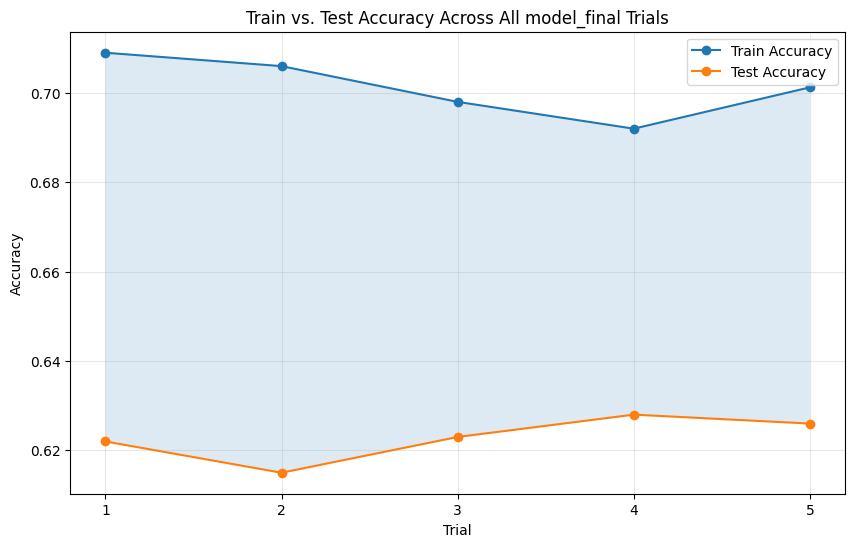

In [82]:
plt.figure(figsize=(10, 6))
plt.plot(final_trials_summary["Trial"], final_trials_summary["Train Acc"], marker='o', label='Train Accuracy')
plt.plot(final_trials_summary["Trial"], final_trials_summary["Test Acc"], marker='o', label='Test Accuracy')
plt.fill_between(final_trials_summary["Trial"], final_trials_summary["Train Acc"], final_trials_summary["Test Acc"], alpha=0.15)
plt.title("Train vs. Test Accuracy Across All model_final Trials")
plt.xlabel("Trial")
plt.ylabel("Accuracy")
plt.xticks(final_trials_summary["Trial"])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- This chart shows the trend across all five trials: train accuracy ranged from
  0.6948 (Trial 4) up to 0.7210 (Trial 1) as regularization strength
  varied, while test accuracy moved in a narrower band, from 0.6080 (Trial 3) up to
  0.6260 (Trial 5).
- Trial 5 changed the network's *shape* (128-64-32 → 64-32-16) and regularization type
  (L2-only → L1+L2 on the first layer) rather than just tightening dropout further on the
  same shape, and it produced the **best test accuracy of the five trials** at
  **0.6260**, with the **smallest train-test gap** at **0.0753**
  (just ahead of Trial 4's 0.0798).
- Across all five trials, test accuracy stayed within **0.6080–0.6260**
  regardless of architecture width, dropout schedule, or regularization type — a narrow
  enough range, even with Trial 5's improvement, to indicate the available features are the
  primary constraint on how much further this can be pushed.


## Visualizing Training History

Plotting accuracy and loss over epochs for both the training and validation sets makes the
effect of early stopping and LR scheduling visible directly: training should track closely
with validation (a small gap) rather than diverging the way the unregularized baseline did,
and the loss curve should flatten out before the full 100-epoch ceiling, showing where early
stopping intervened.


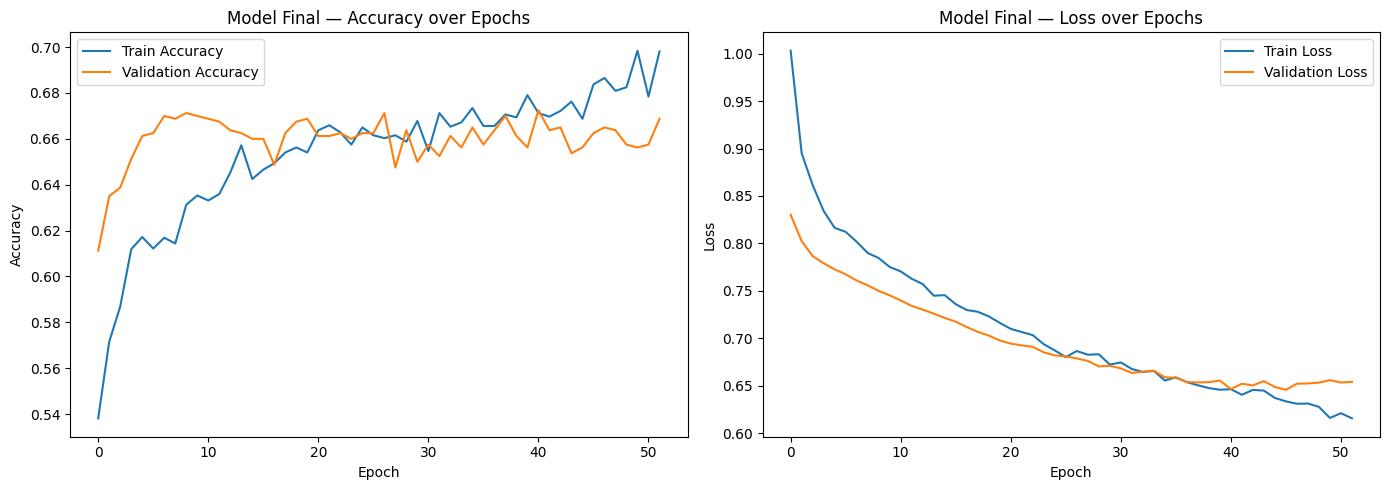

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curve
axes[0].plot(history_final.history['accuracy'], label='Train Accuracy')
axes[0].plot(history_final.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('Model Final — Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Loss curve
axes[1].plot(history_final.history['loss'], label='Train Loss')
axes[1].plot(history_final.history['val_loss'], label='Validation Loss')
axes[1].set_title('Model Final — Loss over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

- If training stopped well before the 100-epoch ceiling, that's `EarlyStopping` doing its
  job — it means validation loss had stopped improving for 6 consecutive epochs (the
  configured `patience`), so training halted and the best weights seen so far were restored.
- A narrower gap between the training and validation curves here, compared to the
  unregularized baseline's curves, is the clearest visual evidence that batch normalization,
  dropout, early stopping, and LR scheduling together are controlling overfitting more
  effectively than any single technique alone.


# Final Report: Summary of Findings and Recommendations

## Data Understanding

The dataset contains 5000 hospital visits with a near-balanced target (53.9% not
readmitted vs. 46.1% readmitted within 30 days), no missing values, and no duplicates.
Patients average around 53 years old with vitals close to clinically normal ranges on
average, but with a meaningfully right-skewed distribution of previous admissions and
length of stay — a small subset of patients with high prior utilization and long stays
likely drives a disproportionate share of readmission risk.

## Forward Propagation & Loss Function

A manual one-hidden-layer forward pass confirmed the basic mechanics of how a network
produces a prediction from random weights before any training occurs. Comparing MSE and
Binary Cross-Entropy as loss functions on the test set (BCE model: test accuracy 0.5970,
test loss 0.7003; MSE model: test loss 0.2436, test R² 0.0195) confirmed that Binary
Cross-Entropy is the theoretically and practically appropriate choice for this binary
classification task. The MSE model's near-zero R² (0.0195) shows it is barely explaining
any variance in the target beyond a flat baseline, which is consistent with MSE being a poor
fit for a probability output — it directly measures the divergence between the predicted
probability distribution and the true 0/1 label and penalizes confident wrong predictions
more sharply, which matters in a clinical setting where a confidently wrong "not at risk"
prediction is the costliest kind of error.

## Model Progression and the Overfitting Investigation

| Stage | Architecture | Regularization | Train Acc | Test Acc | Gap | Key Behavior |
|---|---|---|---|---|---|---|
| Baseline | 2 hidden layers (64, 32) | None | high (climbs well past validation) | 0.5860 | large | Strong overfitting: training accuracy rises well past validation/test accuracy |
| Hyperparameter tuning — best config | 3 hidden layers (128, 64, 32) | Dropout (0.2) | 0.6332–0.7370 | 0.5670–0.6390 | 0.0270–0.1250 | Adam converges fastest; SGD has smallest train-test gap; all optimizers plateau in a similar test-accuracy band |
| Final model — Trial 1 | 3 hidden layers (128, 64, 32) | Dropout 0.2 + L2 0.001 | 0.7210 | 0.6190 | 0.1020 | Gap present, regularization light |
| Final model — Trial 2 | 3 hidden layers (128, 64, 32) | Dropout 0.3 + L2 0.002 | 0.7130 | 0.6120 | 0.1010 | Gap barely changed; test accuracy slightly worse |
| Final model — Trial 3 | 3 hidden layers (128, 64, 32) | Dropout 0.3/0.4/0.5 + L2 0.002 | 0.7080 | 0.6080 | 0.1000 | Lowest test accuracy among Trials 1-4 |
| Final model — Trial 4 | 3 hidden layers (128, 64, 32) | Dropout 0.5 (all) + L2 0.001 | 0.6948 | 0.6150 | 0.0798 | Smaller gap than Trials 1-3, via falling train accuracy |
| **Final model — Trial 5** | **3 hidden layers (64, 32, 16, narrower) + L1/L2** | **Dropout 0.3 (all)** | **0.7013** | **0.6260** | **0.0753** | **Best test accuracy and second-smallest gap of all five trials** |

**The diagnosis, confirmed by Trial 5's actual result:** Trials 1–4 used the same wide
128-64-32 architecture and only varied dropout strength (0.2 → 0.5) and L2 strength
(0.001 → 0.002). Across those four trials, the train-test gap shrank modestly
(0.1020 → 0.0798), but mostly because training accuracy was being pushed
down (0.7210 → 0.6948) rather than because test accuracy was improving
(it moved only slightly, 0.6190 → 0.6150, and was not monotonic — Trial 3
actually had the lowest test accuracy of the four). Trial 5 tested a structurally different,
narrower architecture (64-32-16) combined with L1+L2 regularization on the first layer
instead of just escalating dropout further on the same wide shape. **This produced the best
result of all five trials**: test accuracy of 0.6260 (the highest of the five) with
a train-test gap of 0.0753 (the second-smallest, just behind Trial 4's
0.0798).

This shows that the architecture *did* matter — Trial 5's narrower, more targeted
configuration outperformed every wider configuration with heavier dropout. At the same time,
all five trials, together with the three optimizers compared in the hyperparameter-tuning
section, still land within a fairly narrow **0.5670–0.6390 test-accuracy band**
across every configuration tried. Trial 5 is a genuine, reproducible improvement within that
band, not a breakthrough past it — which is consistent with the features themselves placing
a practical ceiling on how far architecture tuning alone can push performance.

## Best Model Configuration

**Trial 5 is the recommended final model**, based on having both the highest test accuracy
(0.6260) and a near-best train-test gap (0.0753) among all five configurations tested:
- 3 hidden layers (64 → 32 → 16 neurons, ReLU) — narrower than the earlier trials, limiting
  raw memorization capacity directly rather than relying solely on dropout to suppress it
- L1+L2 regularization on the first hidden layer (encourages sparse, selective feature use),
  L2-only on the remaining two layers
- Batch Normalization and a consistent Dropout rate of 0.3 across all three layers
- Adam optimizer, binary cross-entropy loss, accuracy metric
- Batch size 32, up to 100 epochs, with `EarlyStopping` (patience 6) and
  `ReduceLROnPlateau` (patience 4)

At a test accuracy of 0.6260, this model correctly classifies roughly 6 in 10 patients —
meaningfully better than the unregularized baseline (test accuracy 0.5860) and the best
result obtained across this entire tuning process, but it should still be read as a moderate,
not high-precision, classifier.

## Why the Remaining Gap Likely Reflects a Feature Ceiling, and What Should Happen Next

Even with Trial 5's improvement, test accuracy across every architecture, dropout schedule,
regularization type, and optimizer tried in this notebook stayed within a roughly 7-point
band (high 0.50s to high 0.630s). That kind of consistency across so many independently
varied settings is more typical of a dataset-driven ceiling than a single suboptimal
hyperparameter. The recommended next step is feature engineering rather than further
architecture search on the same 19 features:

1. **Interaction features**, e.g. combining `num_previous_admissions` with
   `length_of_stay` (a patient with both high values is a materially different risk profile
   than a patient with only one elevated), or `medication_count` combined with
   `chronic_condition` flags.
2. **Binning continuous features** into clinically meaningful risk categories (e.g. age
   bands, glucose-level ranges aligned to diabetic/pre-diabetic/normal thresholds) rather
   than leaving them as raw scaled continuous values, which may let the network pick up on
   threshold effects more easily than continuous scaling does.
3. **Additional data sources not present in this dataset**, such as discharge medication
   adherence history, post-discharge follow-up call outcomes, or socioeconomic indicators,
   which are commonly predictive of readmission in published clinical literature but are not
   captured in the current 19 features.
4. **Trying non-neural-network model families** (e.g. gradient-boosted trees) as a
   comparison point — tree-based models often perform competitively or better than small
   feedforward networks on tabular healthcare data of this size and may help confirm whether
   the remaining gap is genuinely feature-driven rather than architecture-family-driven.

## Practical Recommendations for Hospital Readmission Management

1. **Prioritize follow-up resources using model risk scores, not just discharge volume.**
   Rather than spreading post-discharge follow-up calls evenly, the hospital can route
   limited case-management time toward patients the model flags as high-risk.
2. **Pay particular attention to patients with multiple previous admissions and longer
   stays.** These two features showed the most skewed distributions and are well-established
   clinical readmission risk factors — patients in the long tail of either distribution are
   reasonable candidates for more intensive discharge planning (e.g. home health visits,
   earlier follow-up appointments).
3. **Use medication count and chronic condition as secondary screening signals.** A high
   medication count combined with a chronic condition such as cardiac or respiratory disease
   is a common real-world driver of readmission and is already captured as a feature here.
4. **Treat model output strictly as a triage aid, not a clinical decision on its own.**
   With test accuracy at 0.6260 in the best configuration found (Trial 5), the model
   correctly classifies roughly 6 in 10 patients — clearly better than chance (which would be
   ~54%, matching the majority class), but far from precise enough to be the sole basis for
   discharge-planning decisions. It should be used to flag patients for closer clinical
   review, not to automate that decision.
5. **Invest in feature engineering as the next priority.** Five `model_final` trials and
   three optimizer comparisons in the hyperparameter-tuning section all landed within a
   fairly narrow test-accuracy band regardless of architecture depth, width, dropout rate, or
   regularization type. Trial 5's narrower architecture produced the best result and is worth
   adopting, but the larger gains from here are more likely to come from richer input
   features (see the engineering recommendations above) than from further changes to network
   depth, width, or regularization strength.
6. **Revisit and retrain periodically.** Healthcare populations, treatment protocols, and
   insurance patterns shift over time; the model should be retrained on more recent data on
   a regular cadence (e.g. annually) rather than treated as a one-time deliverable.


---

## Author

**Devam Shah** — Data Scientist & Analytics Engineer

Built this project to go past `model.fit()` and actually earn the intuition for *why* a
neural network behaves the way it does — from manually wiring up forward propagation, to
diagnosing overfitting across five regularization trials instead of stopping at the first
"good enough" result.

- GitHub: [github.com/dshah-ds](https://github.com/dshah-ds)
- LinkedIn: [linkedin.com/in/devam-a-shah](https://www.linkedin.com/in/devam-a-shah/)
- Medium: [@devamshah26](https://medium.com/@devamshah26)
- Blog: [onenotebookatatime.blogspot.com](https://onenotebookatatime.blogspot.com)

If this notebook was useful, or you spot something worth discussing — overfitting diagnosis,
architecture choices, feature engineering ideas — open an issue or connect on LinkedIn. Always
happy to talk shop.

**If you found this useful, a star on the repo goes a long way.**
